<a href="https://colab.research.google.com/github/MikatekoBuhle/Buhle-Mbokodo-projects-/blob/main/EDAB6808_NLP_Assignment4_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDAB6808 Assignment 4
## Lwazi Nhlapo(2021856345)
## Buhle Mbokodo (2024007920)
## Natural language processing of Bitcoin tweets

**Question 1 — topic modelling (50 marks)** · **Question 2 — sentiment and volatility (50 marks)**

This notebook documents the source, audits the supplied Parquet, repairs its CSV parsing problem from the same cached Kaggle source, and conducts a reproducible, date stratified analysis. All statistical findings concern the **sampled, English-classified tweets**. They are not estimates of all Twitter activity.


### Findings from analysis

- **Six NMF topics:** crypto/altcoin news, game posts, reward-faucet claims, project promotion, trading discussion and NFT/altcoin communities.
- **Sentiment comparison:** frozen Twitter RoBERTa agrees with **44/60 human labels (73.3%)**, versus **38/60 (63.3%)** for unmodified VADER. Macro-F1 improves from **0.582 to 0.666**. The exact paired test has **p = 0.238**; this small, imbalanced selection sample does not establish a definitive population-level winner.
- **Core Q2 finding:** adding RoBERTa sentiment to market and tweet-activity controls reduces Ridge holdout MAE by **0.78%**, compared with a **0.52% deterioration** for VADER. RoBERTa's conditional 95% interval for the MAE difference is **[−0.00018626, +0.00000034]**, which includes zero; it improves **1/4** chronological validation folds. The training-mean benchmark still has the lowest holdout MAE. Better sentiment classification therefore gives **only tentative, inconsistent forecasting evidence**.
- **Scope:** 24,187 English-classified sampled tweets, 201 modelling dates and a 41-origin holdout. The transformer extension is retrospective/exploratory; supplied timestamp authenticity remains unverified. Associations are not causal effects.


## 1. Setup and reproducibility
Versions are recorded, the random seed is fixed, and figures and evidence tables are exported. Library installation is conditional; no credentials or personal machine paths are required for the analysis. The recovery utility accepts a local source CSV or the original Kaggle cache.

In [ ]:
import importlib.util, subprocess, sys, os
required={'numpy':'numpy','pandas':'pandas','pyarrow':'pyarrow','sklearn':'scikit-learn',
          'scipy':'scipy','matplotlib':'matplotlib','vaderSentiment':'vaderSentiment',
          'langdetect':'langdetect','emoji':'emoji','yfinance':'yfinance','nbformat':'nbformat','wordcloud':'wordcloud'}
missing=[package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
os.environ.setdefault('MPLCONFIGDIR', '/tmp/edab6808-matplotlib')
from pathlib import Path
import json, re, html, hashlib, warnings, time, csv
from collections import Counter
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
from scipy.optimize import linear_sum_assignment
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF, LatentDirichletAllocation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, confusion_matrix, classification_report
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from langdetect import detect_langs, DetectorFactory
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import emoji
SEED=6808
DetectorFactory.seed=SEED
ROOT=Path.cwd()
DATA=ROOT/'data'; OUT=ROOT/'outputs'; FIG=ROOT/'figures'
if not (DATA/'data_provenance.json').exists() and (ROOT/'EDAB6808_notebook_bundle.zip').exists():
    import zipfile
    with zipfile.ZipFile(ROOT/'EDAB6808_notebook_bundle.zip') as bundle:
        for member in bundle.infolist():
            target=(ROOT/member.filename).resolve()
            if ROOT.resolve() not in target.parents:raise ValueError('Unsafe archive member path')
            if member.filename.startswith(('data/','outputs/','figures/')):
                if target.exists():continue  # Preserve existing data and completed human labels.
                bundle.extract(member,ROOT)
for folder in (DATA,OUT,FIG):folder.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',140)
pd.set_option('display.max_columns',16)
COLORS=['#245B78','#C28A22','#9A5578','#69804A','#C56536','#697785','#594F8D','#7C684B','#367F81','#A65359']
plt.rcParams.update({'figure.figsize':(10,4.5),'figure.dpi':110,'font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,
                     'grid.alpha':.18,'axes.prop_cycle':plt.cycler(color=COLORS)})
def finish(name):
    plt.tight_layout();plt.savefig(FIG/f'{name}.png',dpi=160,bbox_inches='tight');plt.show()
def say(text):display(Markdown(text))
import importlib.metadata as im
versions={p:im.version(p) for p in required.values()}
(OUT/'environment_versions.json').write_text(json.dumps(versions,indent=2))
display(pd.Series(versions,name='Version').to_frame())

,Version
numpy,2.3.2
pandas,2.3.2
pyarrow,21.0.0
scikit-learn,1.7.1
scipy,1.16.1
matplotlib,3.10.6
vaderSentiment,3.3.2
langdetect,1.0.9
emoji,2.16.0
yfinance,1.2.0


## 2. Source integrity, repair and modelling population — Q1.1; Q2.1

Source: [Kaggle, Bitcoin Tweets Dataset 2025–2026](https://www.kaggle.com/datasets/pokeash/bitcoin-tweets-dataset-20252026), cached version 1. The supplied `bitcoin_tweets.parquet` was created with `quote_char=None` and `truncate_ragged_lines=True`. This split quoted commas and multiline tweets into unrelated columns/rows. **Date parsing alone cannot repair truncated text.**

The original is preserved. `data/bitcoin_tweets_repaired.parquet` was reconstructed using double-quoted fields and backslash escaping from the same source CSV. Strict parsing failures and wrong field counts are logged by physical source line; malformed records are excluded, never silently truncated. `source_row` identifies a recovered record and is not a Twitter status ID. The supplied-file audit below uses its first row group; it is not a full-corpus corruption-rate estimate.

For feasible Colab execution, random-priority sampling retains at most **150 structurally valid records per observed date** (seed 6808), before language filtering. Selection is uniform within each day, without cherry-picking sentiment. Daily source volumes are measured before sampling. Pooled prevalence uses source-day/sample-day weights; daily sentiment uses within-day means. Equal sample caps do not imply equal source activity.

In [ ]:
provenance=json.loads((DATA/'data_provenance.json').read_text())
display(pd.Series(provenance,name='Value').to_frame())
display(pd.read_csv(DATA/'supplied_parquet_corruption_examples.csv').head(3))
missing_source=pd.read_csv(DATA/'source_missingness.csv').rename(columns={'Unnamed: 0':'Field'})
display(missing_source)
say(f"The malformed supplied Parquet has **{provenance['supplied_parquet_rows']:,} physical rows**. "
    f"Recovery produced **{provenance['recovered_records']:,} correctly shaped records**, with "
    f"**{provenance['csv_rejected_records']:,} parser/field-count rejects** logged separately. "
    f"These are different record definitions; the difference is not a tweet-deletion count.")

,Value
supplied_parquet_rows,22389586
supplied_audit_sample_rows,100000
supplied_sample_date_pattern_failures,87260
supplied_sample_retweet_flag_failures,97567
source_csv,/Users/lwazinhlapo/.cache/kagglehub/datasets/pokeash/bitcoin-tweets-dataset-20252026/versions/1/bitcoin_tweets_latest.csv
source_bytes,2095920736
repair,Strict CSV with double-quote fields and backslash escaping; rejects explicitly logged by physical line; valid multiline fields retained
seed,6808
daily_sample_cap,150
recovered_records,4689305


,user_name,user_location,user_description,user_created,user_followers,user_friends,user_favourites,user_verified,date,text,hashtags,source,is_retweet
0,DeSota Wilson,"""Atlanta","GA""","""Biz Consultant",real estate,fintech,startups,posts are not the view of my employer,RTs are not endorsements,military brat,@UNC alumnus,ΚΑΨ♦️ΦΝΠ,"-DW = Me"""
1,CryptoND,NaN,😎 BITCOINLIVE is a Dutch platform aimed at informing the general public about crypto & technology! 😉 AND promoting it: https://t.co/5RYd...,2019-10-17 20:12:10,6769.0,1532,25483,False,2026-02-10 23:58:48,"""😎 Today",that's this #Thursday,"we will do a \""🎬 Take 2\"" with our friend @LeoWandersleb","#Btc #wallet #security expe… https://t.co/go6aDgRml5"""
2,Tdlmatias,"""London","England""","""IM Academy : The best #forex",#SelfEducation,"#Cryptocurrency trading education platform: https://t.co/LUr56q3Q19 🙋‍♂️ 💰 💰in the World 🗺..""",2014-11-10 10:50:37,128.0,332,924,False,2026-02-10 23:54:48,"""Guys evening"


,Field,empty_fields
0,source_row,0
1,user_name,108
2,user_location,2338536
3,user_description,519937
4,user_created,66
5,user_followers,0
6,user_friends,0
7,user_favourites,0
8,user_verified,0
9,date,66


The malformed supplied Parquet has **22,389,586 physical rows**. Recovery produced **4,689,305 correctly shaped records**, with **51 parser/field-count rejects** logged separately. These are different record definitions; the difference is not a tweet-deletion count.

### 2.1 Rebuild the corrected full Parquet if necessary
This optional cell contains the exact recovery implementation, for provenance and reproducibility. It is not rerun by default because the supplied cached analysis sample and audit outputs already exist. Set `REBUILD_SOURCE=True` only when the original CSV is available; edit the `SOURCE` setting in the code if your CSV is elsewhere. Recovery failures are recorded in `csv_rejected_records.csv`.

In [ ]:
REBUILD_SOURCE=False
"""Recover correctly quoted source records and build a bounded daily sample.

The supplied Parquet is preserved. This utility does not infer lost fields from
its truncated rows: it re-parses the cached source CSV with its escape dialect.
"""
from pathlib import Path
import json, hashlib, time, csv, zipfile
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

ROOT = Path.cwd()
SOURCE = Path.home()/'.cache/kagglehub/datasets/pokeash/bitcoin-tweets-dataset-20252026/versions/1/bitcoin_tweets_latest.csv'
REPAIR_OUT = ROOT/'data'
OUT = REPAIR_OUT
OUT.mkdir(exist_ok=True)
PER_DAY = 150
SEED = 6808

def main():
    global SOURCE
    local_candidates=[ROOT/'bitcoin_tweets_latest.csv',OUT/'bitcoin_tweets_latest.csv']
    for candidate in local_candidates:
        if candidate.exists():SOURCE=candidate;break
    if not SOURCE.exists() and (ROOT/'Bitcoin.zip').exists():
        with zipfile.ZipFile(ROOT/'Bitcoin.zip') as archive:
            # Extract only the known dataset member, never arbitrary archive paths.
            with archive.open('bitcoin_tweets_latest.csv') as incoming, (OUT/'bitcoin_tweets_latest.csv').open('wb') as target:
                for block in iter(lambda:incoming.read(8*1024*1024),b''):target.write(block)
        SOURCE=OUT/'bitcoin_tweets_latest.csv'
    original = pq.ParquetFile(ROOT/'bitcoin_tweets.parquet')
    first = original.read_row_group(0).to_pandas()
    valid_date = first['date'].astype(str).str.fullmatch(r'\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}')
    valid_flag = first['is_retweet'].isin(['True','False'])
    audit = {'supplied_parquet_rows':original.metadata.num_rows,
             'supplied_audit_sample_rows':len(first),
             'supplied_sample_date_pattern_failures':int((~valid_date).sum()),
             'supplied_sample_retweet_flag_failures':int((~valid_flag).sum()),
             'source_csv':str(SOURCE), 'source_bytes':SOURCE.stat().st_size,
             'repair':'CSV quotechar=double quote, escapechar=backslash; multiline records retained; no bad-line skipping',
             'seed':SEED, 'daily_sample_cap':PER_DAY}
    first.head(10).to_csv(OUT/'supplied_parquet_corruption_examples.csv',index=False)
    rng=np.random.default_rng(SEED)
    sample=pd.DataFrame(); daily_parts=[]; writer=None; total=0; bad_dates=0; empty_text=0; flag_bad=0
    nulls=None; start=time.time()
    rejects=[]; parsed_records=0
    def validated_chunks():
        nonlocal parsed_records
        csv.field_size_limit(1_000_000)
        with SOURCE.open(newline='',encoding='utf-8') as stream:
            reader=csv.reader(stream,escapechar='\\',quotechar='"',strict=True)
            columns=next(reader); rows=[]
            while True:
                line_start=reader.line_num+1
                try: row=next(reader)
                except StopIteration: break
                except csv.Error as error:
                    rejects.append({'line_start':line_start,'line_end':reader.line_num,'reason':str(error)})
                    continue
                parsed_records+=1
                if len(row)!=len(columns):
                    rejects.append({'line_start':line_start,'line_end':reader.line_num,'reason':f'field_count={len(row)}'})
                    continue
                rows.append(row)
                if len(rows)==100_000:
                    yield pd.DataFrame(rows,columns=columns);rows=[]
            if rows:yield pd.DataFrame(rows,columns=columns)
    try:
        for chunk in validated_chunks():
            chunk.insert(0,'source_row',np.arange(total+1,total+len(chunk)+1,dtype=np.int64))
            total+=len(chunk)
            missing=chunk.eq('').sum(); nulls=missing if nulls is None else nulls.add(missing,fill_value=0)
            dates=pd.to_datetime(chunk['date'],format='%Y-%m-%d %H:%M:%S',errors='coerce',utc=True)
            text_ok=chunk['text'].str.strip().ne('')
            flag_ok=chunk['is_retweet'].isin(['True','False'])
            bad_dates+=int(dates.isna().sum()); empty_text+=int((~text_ok).sum());flag_bad+=int((~flag_ok).sum())
            table=pa.Table.from_pandas(chunk,preserve_index=False)
            if writer is None:writer=pq.ParquetWriter(OUT/'bitcoin_tweets_repaired.parquet',table.schema,compression='zstd')
            writer.write_table(table,row_group_size=100_000)
            chunk['timestamp']=dates
            good=chunk.loc[dates.notna() & text_ok & flag_ok].copy()
            good['day']=good['timestamp'].dt.floor('D')
            good['sample_priority']=rng.random(len(good))
            daily_parts.append(good.groupby('day').size())
            # Random-key sampling: each source record has equal inclusion chance within its day.
            candidates=good.sort_values('sample_priority').groupby('day',sort=False).head(PER_DAY)
            sample=pd.concat([sample,candidates],ignore_index=True)
            sample=sample.sort_values('sample_priority').groupby('day',sort=False).head(PER_DAY)
            if total%500_000==0:print(f'Recovered {total:,} records; {sample.day.nunique()} dates; {time.time()-start:.0f}s',flush=True)
    finally:
        if writer is not None:writer.close()
    daily=pd.concat(daily_parts).groupby(level=0).sum().sort_index().rename('source_valid_records').reset_index()
    sample=sample.sort_values(['day','sample_priority']).reset_index(drop=True)
    sample.to_parquet(OUT/'daily_stratified_sample.parquet',index=False)
    daily.to_csv(OUT/'source_daily_counts.csv',index=False)
    nulls.rename('empty_fields').to_csv(OUT/'source_missingness.csv')
    pd.DataFrame(rejects).to_csv(OUT/'csv_rejected_records.csv',index=False)
    audit['repair']='Strict CSV with double-quote fields and backslash escaping; rejects explicitly logged by physical line; valid multiline fields retained'
    audit.update({'recovered_records':total,'csv_rejected_records':len(rejects),'parsed_records':parsed_records,'invalid_dates':bad_dates,'empty_text':empty_text,
                  'invalid_retweet_flags':flag_bad,'sample_records':len(sample),
                  'date_min':str(sample.timestamp.min()),'date_max':str(sample.timestamp.max()),
                  'dates':int(len(daily))})
    h=hashlib.sha256()
    with SOURCE.open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    audit['source_sha256']=h.hexdigest()
    (OUT/'data_provenance.json').write_text(json.dumps(audit,indent=2))
    print(json.dumps(audit,indent=2),flush=True)

if REBUILD_SOURCE:
    main()
OUT=ROOT/'outputs'

### 2.2 Analysis sample, exclusions and duplicate policy
The model population is the supplied sample restricted to nonempty text and dates, unique `(user_name, timestamp, raw_text)` records, and confidently English-classified content. Language classification is imperfect on short texts, so short/uncertain texts are excluded and counts are reported. This is a defensible language restriction for English topic features and VADER; conclusions do not generalise to excluded languages.

Duplicate messages from different accounts/times remain in prevalence and sentiment. Topic fitting deduplicates cleaned message text to reduce copied-message dominance, then assigns topics back to eligible sampled tweets. Retweets are retained and flagged. Sampling precedes deduplication, so exclusions and weights approximate the sampled source population; they do not turn this convenience dataset into a random sample of all Twitter.

In [ ]:
sample=pd.read_parquet(DATA/'daily_stratified_sample.parquet')
sample['timestamp']=pd.to_datetime(sample['timestamp'],utc=True)
sample['day']=sample['timestamp'].dt.floor('D')
daily_source=pd.read_csv(DATA/'source_daily_counts.csv',parse_dates=['day'])
daily_source['day']=pd.to_datetime(daily_source['day'],utc=True)
raw_n=len(sample)
sample=sample.dropna(subset=['timestamp','text']).copy()
sample=sample[sample['text'].str.strip().ne('')].copy()
dups=sample.duplicated(['user_name','timestamp','text'])
duplicate_n=int(dups.sum());sample=sample.loc[~dups].copy()
sample['is_retweet_flag']=sample['is_retweet'].eq('True') | sample['text'].str.match(r'^\s*RT\s+@',case=False)
def language_text(text):
    text=html.unescape(str(text))
    text=re.sub(r'https?://\S+|www\.\S+|@\w+|[#\$]\w+',' ',text)
    return re.sub(r'\s+',' ',text).strip()
def identify_language(text):
    text=language_text(text)
    if len(re.findall(r'[A-Za-z]+',text))<5:return ('uncertain',0.)
    try:
        result=detect_langs(text)[0]
        return (result.lang,float(result.prob))
    except Exception:return ('uncertain',0.)
cache=DATA/'language_labels.parquet'
fingerprint=hashlib.sha256(('langdetect-1.0.9|seed6808|v1|'+ '|'.join(sample['source_row'].astype(str))).encode()).hexdigest()
cache_key=DATA/'language_cache_key.txt'
if cache.exists() and cache_key.exists() and cache_key.read_text()==fingerprint:
    languages=pd.read_parquet(cache)
else:
    results=[identify_language(t) for t in sample['text']]
    languages=pd.DataFrame(results,columns=['language','language_probability'])
    languages['source_row']=sample['source_row'].to_numpy()
    languages.to_parquet(cache,index=False);cache_key.write_text(fingerprint)
sample=sample.merge(languages,on='source_row',validate='one_to_one')
sample['eligible_english']=sample['language'].eq('en') & sample['language_probability'].ge(.90)
lang_summary=sample.groupby('language').size().sort_values(ascending=False).rename('Sampled_records')
tweets=sample.loc[sample['eligible_english']].copy().reset_index(drop=True)
day_sample_counts=sample.groupby('day').size().rename('sample_records')
tweets=tweets.merge(daily_source,on='day',validate='many_to_one')
tweets['sampling_weight']=tweets['source_valid_records']/tweets['day'].map(day_sample_counts)
flow=pd.DataFrame({'Stage':['Stratified sample','Duplicate record exclusions','After duplicate removal',
                           'Eligible English','Other language/uncertain exclusions'],
                   'Records':[raw_n,duplicate_n,len(sample),len(tweets),len(sample)-len(tweets)]})
display(flow);display(lang_summary.head(12).to_frame())
flow.to_csv(OUT/'population_flow.csv',index=False)
lang_summary.to_csv(OUT/'language_distribution.csv')
assert tweets.source_row.is_unique and tweets.timestamp.notna().all()
say(f"The analysis uses **{len(tweets):,} English-classified sampled tweets** across "
    f"**{tweets.day.nunique()} dates**, from {tweets.timestamp.min().date()} to {tweets.timestamp.max().date()}. "
    "This is the stated modelling population; all later exclusions are reported separately.")

,Stage,Records
0,Stratified sample,30083
1,Duplicate record exclusions,0
2,After duplicate removal,30083
3,Eligible English,24187
4,Other language/uncertain exclusions,5896


,Sampled_records
language,
en,25305
uncertain,3962
ro,188
de,154
fr,75
ca,52
af,43
cy,34
nl,32


The analysis uses **24,187 English-classified sampled tweets** across **201 dates**, from 2025-03-06 to 2026-03-02. This is the stated modelling population; all later exclusions are reported separately.

### 2.3 Timestamp credibility and coverage
The CSV timestamps have no timezone. We interpret them as **UTC**, explicitly as an assumption, to match market-day boundaries. Some tweet text refers to older years despite 2025–2026 record dates. An old-year mention can be retrospective; it does not prove a timestamp error. Nevertheless, authentic contemporaneous timing is not independently established. The volatility exercise is therefore **conditional on the supplied timestamps being authentic** and cannot establish reliable real-world forecasting or causal impact. Dates are not shifted to force agreement.

In [ ]:
year_refs=sample['text'].str.findall(r'\b20(?:1\d|2\d)\b')
old_year_mask=pd.Series([any(int(y)<d.year-1 for y in ys) for ys,d in zip(year_refs,sample.timestamp)],index=sample.index)
date_examples=sample.loc[old_year_mask,['source_row','timestamp','text']].head(12)
date_examples.to_csv(OUT/'timestamp_credibility_examples.csv',index=False)
display(date_examples.head(5))
full_dates=pd.date_range(daily_source.day.min(),daily_source.day.max(),freq='D',tz='UTC')
missing_dates=full_dates.difference(daily_source.day)
say(f"**{old_year_mask.sum():,}/{len(sample):,}** sampled records mention a year at least two years before their record year. "
    f"There are **{len(missing_dates)} dates with no structurally valid source records** inside the observed range. "
    "Year mentions are an audit flag, not a verified correction. Missing dates remain missing, not neutral sentiment.")
pd.DataFrame({'missing_source_date':missing_dates}).to_csv(OUT/'missing_source_dates.csv',index=False)

,source_row,timestamp,text
4,2430843,2025-03-06 17:46:10+00:00,@LionUnivers0 @DeadApeClub #creoengineDeveloping and deploying games is easy now 🚀⚡Best #Decentralised platform for game developers and ...
9,2433355,2025-03-06 15:14:22+00:00,📢10 Best Crypto Staking Platforms Enthusiasts Should Use In 2022\n\n📋 Curated post from Publish0x\n💎 Read or write articles and get 💰 #c...
20,2430828,2025-03-06 17:46:56+00:00,@Ladimeji3 @SmallBrosNFT #creoengineDeveloping and deploying games is easy now 🚀⚡Best #Decentralised platform for game developers and al...
23,2428168,2025-03-06 20:45:00+00:00,"Top 10 #Cryptocurrency Live Prices: \n(03:45 PM . Mar 06,2022)\n\n#BTC $38849.35\n#ETH $2619.63\n#BNB $378.87\n#DOGE $0.12\n#SHIB $0.000..."
60,2431318,2025-03-06 17:14:17+00:00,@ibrahim60069873 @DoyoungPromotes @CyrusNFTer the best metaverse project of the future 🚀🚀\n@Metamoonft 👈👈\n\n#metamoonnft #Metaverse #we...


**1,599/30,083** sampled records mention a year at least two years before their record year. There are **161 dates with no structurally valid source records** inside the observed range. Year mentions are an audit flag, not a verified correction. Missing dates remain missing, not neutral sentiment.

## 3. Exploratory analysis and task-specific cleaning — Q1.2–3; Q2.2
URLs and mentions are removed; hashtag and cashtag **words** are retained. HTML entities are decoded. Topic text is lowercased, decorative emojis are removed rather than expanded into misleading words, English stopwords and universal `bitcoin`/`btc` tokens are removed, and words shorter than three letters are omitted. We preserve domain words such as mining, bearish, bullish, ETF and regulation. No aggressive stemming is applied. Pure numbers and long identifiers are removed from topic text; raw text is preserved for inspection.

Sentiment text keeps negation, punctuation, capitalisation and emojis, strips URLs/mentions and hashtag markers, and is scored using **unmodified VADER**. No unvalidated crypto scores are inserted into its lexicon. These choices trade domain sensitivity for a transparent, reproducible baseline that must be checked by humans.

In [ ]:
TOPIC_STOP=set(ENGLISH_STOP_WORDS)|{'bitcoin','btc','rt','amp','https','http','www','com','co','t','s','don','ve','ll'}
def clean_topic(text):
    text=html.unescape(str(text))
    text=re.sub(r'https?://\S+|www\.\S+|@\w+',' ',text)
    text=emoji.replace_emoji(text,replace=' ')
    text=re.sub(r'\b[0-9a-fA-F]{20,}\b',' ',text)
    tokens=re.findall(r'[a-z]{3,}',text.lower())
    return ' '.join(t for t in tokens if t not in TOPIC_STOP)
def clean_sentiment(text):
    text=html.unescape(str(text))
    text=re.sub(r'^\s*RT\s+@\w+:?',' ',text,flags=re.I)
    text=re.sub(r'https?://\S+|www\.\S+|@\w+',' ',text)
    text=re.sub(r'[#\$](\w+)',r'\1',text)
    return re.sub(r'\s+',' ',text).strip()
tweets['cleaned_text']=tweets['text'].map(clean_topic)
tweets['sentiment_text']=tweets['text'].map(clean_sentiment)
tweets['topic_token_count']=tweets.cleaned_text.str.split().str.len()
topic_eligible=tweets.topic_token_count.ge(3)
topic_docs=tweets.loc[topic_eligible].drop_duplicates('cleaned_text').copy()
clean_examples=tweets[['source_row','text','cleaned_text','sentiment_text']].head(8)
display(clean_examples);clean_examples.to_csv(OUT/'cleaning_examples.csv',index=False)
say(f"Topic fitting has **{len(topic_docs):,} unique cleaned messages**. "
    f"**{(~topic_eligible).sum():,}** English sampled tweets have fewer than three retained topic tokens and will be unassigned. "
    "Repeated messages are still retained when calculating sentiment and topic prevalence.")

,source_row,text,cleaned_text,sentiment_text
0,2433450,Great application for free or paid mining\nhttps://t.co/J8RgoSXu4K\n#BTC\n#free #Crypto,great application free paid mining free crypto,Great application for free or paid mining BTC free Crypto
1,2431981,Would you rather have 1 million dollars is bitcoin (~25 BTC) or these following options. ⬇️ #Bitcoin #BTC #crypto #NFT #NFTs #cars #Altc...,million dollars following options crypto nft nfts cars altcoins cryptocurrency binance eth,Would you rather have 1 million dollars is bitcoin (~25 BTC) or these following options. ⬇️ Bitcoin BTC crypto NFT NFTs cars Altcoins cr...
2,2433316,$detf will be launch the 25th of March !\nCan't wait to watch the revolution it will make at the crypto space!\n\nOne fully decentralize...,detf launch march wait watch revolution make crypto space fully decentralized etf let crypto ethereum nftcollector nftart bnb luna ftm e...,detf will be launch the 25th of March ! Can't wait to watch the revolution it will make at the crypto space! One fully decentralized ETF...
3,2427602,@Tronmining2 Wooooow l Love you that wow #cryptocurrecy #BTC #Ethereum #shiba #Dog #SOL #BNB #BSC https://t.co/NdGYBjdXFR,wooooow love wow cryptocurrecy ethereum shiba dog sol bnb bsc,Wooooow l Love you that wow cryptocurrecy BTC Ethereum shiba Dog SOL BNB BSC
4,2430843,@LionUnivers0 @DeadApeClub #creoengineDeveloping and deploying games is easy now 🚀⚡Best #Decentralised platform for game developers and ...,creoenginedeveloping deploying games easy best decentralised platform game developers serves developing games nft marketplace providertg...,creoengineDeveloping and deploying games is easy now 🚀⚡Best Decentralised platform for game developers and also serves for developing ga...
5,2430756,"Sticking with the Russia case study, Russians fleeing are not going to carry gold across the border, and carrying more than 10k USD is i...",sticking russia case study russians fleeing going carry gold border carrying usd illegal swift cards panic steps keywords paper stoke va...,"Sticking with the Russia case study, Russians fleeing are not going to carry gold across the border, and carrying more than 10k USD is i..."
6,2432570,@PlayerPix Same. Green #BTC will pump to 30% from here. DCA now holders,green pump dca holders,Same. Green BTC will pump to 30% from here. DCA now holders
7,2432232,WELP!! 🤣🤣 When You call out these Psychos who pump and dump on their followers !\n\n#BTC #CRYPTO #DEGEN #FAKEFLUENCER #SHITCOIN #PUMP #D...,welp psychos pump dump followers crypto degen fakefluencer shitcoin pump dump,WELP!! 🤣🤣 When You call out these Psychos who pump and dump on their followers ! BTC CRYPTO DEGEN FAKEFLUENCER SHITCOIN PUMP DUMP


Topic fitting has **20,015 unique cleaned messages**. **421** English sampled tweets have fewer than three retained topic tokens and will be unassigned. Repeated messages are still retained when calculating sentiment and topic prevalence.

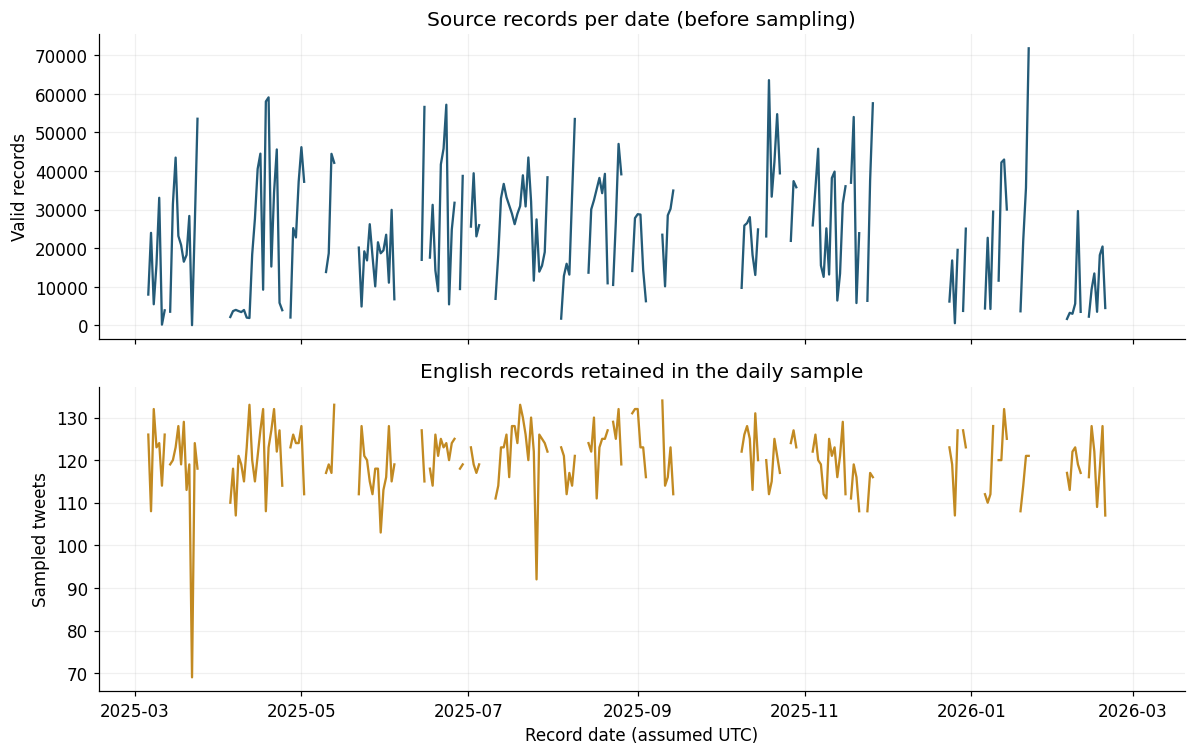

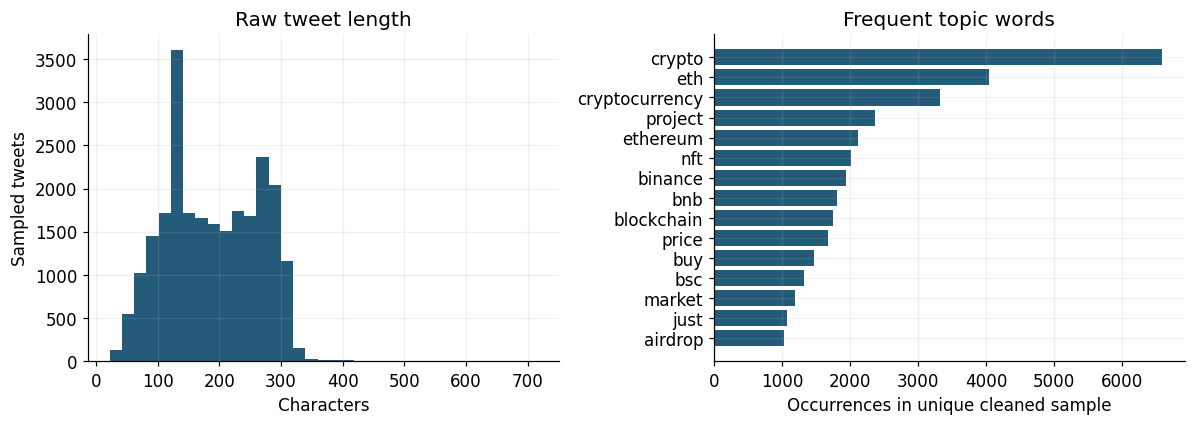

,Measure,Share
0,Contains URL,0.560797
1,Contains hashtag,0.978542
2,Retweet marker,0.000000
3,Contains emoji,0.311986


The median source count is **23,064 records/day**, whereas the analysis sample is capped at 150 before filtering. Source-volume changes may reflect collection coverage; sample volume is a coverage indicator, not public attention. The most frequent retained terms are **crypto, eth, cryptocurrency, project, ethereum**; topic models test whether these form distinct themes.

In [ ]:
fig,ax=plt.subplots(2,1,figsize=(11,7),sharex=True)
source_series=daily_source.set_index('day').source_valid_records.reindex(full_dates)
ax[0].plot(source_series.index,source_series,color=COLORS[0]);ax[0].set(title='Source records per date (before sampling)',ylabel='Valid records')
daily_english=tweets.groupby('day').size().reindex(full_dates)
ax[1].plot(daily_english.index,daily_english,color=COLORS[1]);ax[1].set(title='English records retained in the daily sample',ylabel='Sampled tweets',xlabel='Record date (assumed UTC)')
finish('01_source_and_sample_coverage')
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].hist(tweets.text.str.len(),bins=35,color=COLORS[0]);ax[0].set(title='Raw tweet length',xlabel='Characters',ylabel='Sampled tweets')
terms=Counter(' '.join(topic_docs.cleaned_text).split()).most_common(15)
ax[1].barh([x[0] for x in terms][::-1],[x[1] for x in terms][::-1],color=COLORS[0]);ax[1].set(title='Frequent topic words',xlabel='Occurrences in unique cleaned sample')
finish('02_lengths_and_terms')
characteristics=pd.DataFrame({'Measure':['Contains URL','Contains hashtag','Retweet marker','Contains emoji'],
    'Share':[tweets.text.str.contains(r'https?://',regex=True).mean(),tweets.text.str.contains('#',regex=False).mean(),
             tweets.is_retweet_flag.mean(),tweets.text.map(lambda t:bool(emoji.emoji_count(t))).mean()]})
display(characteristics)
characteristics.to_csv(OUT/'text_characteristics.csv',index=False)
say(f"The median source count is **{daily_source.source_valid_records.median():,.0f} records/day**, "
    f"whereas the analysis sample is capped at {provenance['daily_sample_cap']} before filtering. "
    "Source-volume changes may reflect collection coverage; sample volume is a coverage indicator, not public attention. "
    f"The most frequent retained terms are **{', '.join(t for t,_ in terms[:5])}**; topic models test whether these form distinct themes.")

## 4. Two representations and two topic methods — Q1.4–6
**Count vectors + LDA** model word counts; **TF–IDF + NMF** factorise weighted term importance. Both use the same vocabulary and a reproducible selection sample, so their coherence is evaluated against the same document co-occurrence evidence. Unigrams and bigrams preserve terms and short phrases. Sampling is explicit; it is not claimed that every source tweet trained the model.

We compare 4, 6, 8 and 10 topics for **each** method, using two random seeds. Selection combines normalised pointwise mutual information (NPMI) coherence, unique top-term diversity and one-to-one matched Jaccard stability. NPMI uses document presence and assigns −1 to unobserved pairs. Reconstruction error and perplexity are method-specific diagnostics and are not compared across methods. Equal criterion ranks are a transparent heuristic, not an optimality proof. Final interpretation also requires checking actual tweets. Warnings are recorded rather than globally hidden.

### 4.1 Prepare count and TF–IDF matrices

In [ ]:
# Fixed sample and vocabulary: unchanged from the original analysis.
selection=topic_docs.sample(n=min(5000,len(topic_docs)),random_state=SEED)
vectorizer=CountVectorizer(max_features=4000,min_df=5,max_df=.65,ngram_range=(1,2))
X_count=vectorizer.fit_transform(selection.cleaned_text)
tfidf=TfidfTransformer(sublinear_tf=True)
X_tfidf=tfidf.fit_transform(X_count)
feature_names=vectorizer.get_feature_names_out()
B=(X_count>0).astype(np.float64);dfreq=np.asarray(B.sum(axis=0)).ravel();n_docs=X_count.shape[0]

### 4.2 Define coherence, diversity and seed stability

In [ ]:
# Co-occurrence NPMI and Hungarian-matched top-word Jaccard use the same definitions.
def top_ids(model,n=10):return np.argsort(model.components_,axis=1)[:,-n:][:,::-1]
def quality(model):
    tops=top_ids(model);values=[]
    for ids in tops:
        co=(B[:,ids].T@B[:,ids]).toarray()
        for a in range(1,len(ids)):
            for b in range(a):
                joint=co[a,b]/n_docs
                if joint<=0:values.append(-1.)
                elif joint>=1:values.append(0.)
                else:values.append(np.log(joint/((dfreq[ids[a]]/n_docs)*(dfreq[ids[b]]/n_docs)))/(-np.log(joint)))
    return float(np.mean(values)),len(set(tops.ravel()))/tops.size
def stability(m1,m2):
    sets1=[set(x) for x in top_ids(m1)];sets2=[set(x) for x in top_ids(m2)]
    score=np.array([[len(a&b)/len(a|b) for b in sets2] for a in sets1])
    row,col=linear_sum_assignment(-score)
    return float(score[row,col].mean())

### 4.3 Define candidate models

In [ ]:
# Keep hyperparameters unchanged so refactoring cannot alter results.
def make_topic_model(method,k,seed):
    if method=='NMF':return NMF(n_components=k,init='nndsvdar',random_state=seed,max_iter=450)
    return LatentDirichletAllocation(n_components=k,learning_method='batch',max_iter=20,random_state=seed,n_jobs=1,evaluate_every=5,perp_tol=.01)

### 4.4 Fit the two methods across topic counts

In [ ]:
# Evaluate each configuration with two fixed seeds; capture convergence warnings.
selection_rows=[];candidate_words=[]
for method in ['LDA','NMF']:
    X=X_count if method=='LDA' else X_tfidf
    for k in [4,6,8,10]:
        models=[];messages=[]
        for seed in [SEED,42]:
            m=make_topic_model(method,k,seed)
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always');m.fit(X)
            messages.extend(str(w.message) for w in caught);models.append(m)
        coherence,diversity=quality(models[0]);stable=stability(*models)
        selection_rows.append({'method':method,'topics':k,'npmi':coherence,'diversity':diversity,'stability':stable,
                               'iterations':models[0].n_iter_,'warning_count':len(messages),
                               'warnings':' | '.join(set(messages)),
                               'method_specific_loss':models[0].reconstruction_err_ if method=='NMF' else models[0].perplexity(X)})
        for topic,ids in enumerate(top_ids(models[0])):
            candidate_words.append({'method':method,'topics':k,'topic':topic,'keywords':', '.join(feature_names[ids])})
        print(f'{method}, k={k}: NPMI={coherence:.3f}, diversity={diversity:.3f}, stability={stable:.3f}',flush=True)

LDA, k=4: NPMI=0.144, diversity=0.775, stability=0.557


LDA, k=6: NPMI=0.111, diversity=0.717, stability=0.291


LDA, k=8: NPMI=0.212, diversity=0.700, stability=0.354


LDA, k=10: NPMI=0.055, diversity=0.630, stability=0.307


NMF, k=4: NPMI=0.608, diversity=0.975, stability=1.000


NMF, k=6: NPMI=0.471, diversity=0.950, stability=1.000


NMF, k=8: NPMI=0.475, diversity=0.950, stability=0.698


NMF, k=10: NPMI=0.468, diversity=0.930, stability=0.802


### 4.5 Rank candidates and inspect their keywords

In [ ]:
# Lower mean rank is better. Method-specific losses are not compared across methods.
topic_selection=pd.DataFrame(selection_rows)
for criterion in ['npmi','diversity','stability']:topic_selection[criterion+'_rank']=topic_selection[criterion].rank(ascending=False)
topic_selection['mean_rank']=topic_selection[[c+'_rank' for c in ['npmi','diversity','stability']]].mean(axis=1)
topic_selection=topic_selection.sort_values(['mean_rank','topics','method']).reset_index(drop=True)
display(topic_selection.drop(columns='warnings'))
topic_selection.to_csv(OUT/'topic_model_selection.csv',index=False)
pd.DataFrame(candidate_words).to_csv(OUT/'candidate_topic_keywords.csv',index=False)
SELECTED_METHOD=str(topic_selection.iloc[0]['method']);SELECTED_K=int(topic_selection.iloc[0]['topics'])
say(f"The quantitative rank rule shortlists **{SELECTED_METHOD} with {SELECTED_K} topics**. "
    "Its keyword table must also be checked for under-segmentation and promotional-template dominance.")
display(pd.DataFrame(candidate_words).query("method == 'NMF' and topics in [4,6]").reset_index(drop=True))
display(pd.DataFrame(candidate_words).query("method == 'LDA' and topics == 6").reset_index(drop=True))
say('At six topics LDA repeats broad crypto/ETH/price vocabulary across multiple clusters, while NMF separates gaming, reward faucets, promotions, trading and NFT terms. LDA reached its 20-iteration cap in these runs; this is a bounded comparison, not proof that no better-tuned LDA model could compete. Seed stability is not resampling stability.')

,method,topics,npmi,diversity,stability,iterations,warning_count,method_specific_loss,npmi_rank,diversity_rank,stability_rank,mean_rank
0,NMF,4,0.607794,0.975000,1.000000,19,0,69.394373,1.0,1.0,1.5,1.166667
1,NMF,6,0.470531,0.950000,1.000000,174,0,69.022158,3.0,2.5,1.5,2.333333
2,NMF,8,0.474579,0.950000,0.697511,63,0,68.724174,2.0,2.5,4.0,2.833333
3,NMF,10,0.468189,0.930000,0.802331,225,0,68.446459,4.0,4.0,3.0,3.666667
4,LDA,4,0.143990,0.775000,0.557110,20,0,1302.130629,6.0,5.0,5.0,5.333333
5,LDA,8,0.212046,0.700000,0.353722,20,0,1309.689683,5.0,7.0,6.0,6.000000
6,LDA,6,0.110899,0.716667,0.290518,20,0,1327.428946,7.0,6.0,8.0,7.000000
7,LDA,10,0.055412,0.630000,0.307330,20,0,1319.658795,8.0,8.0,7.0,7.666667


The quantitative rank rule shortlists **NMF with 4 topics**. Its keyword table must also be checked for under-segmentation and promotional-template dominance.

,method,topics,topic,keywords
0,NMF,4,0,"crypto, eth, cryptocurrency, ethereum, blockchain, nft, binance, cryptonews, crypto cryptocurrency, bnb"
1,NMF,4,1,"playing coinhuntworld, join playing, awesome cryptocurrency, coinhuntworld, coinhuntworld awesome, location join, vault location, vault,..."
2,NMF,4,2,"lightning, sats, lightning sats, free lightning, faucet, unlock, free, lightningnetwork, lightningnetwork boltcoiner, boltcoiner"
3,NMF,4,3,"project, airdrop, bsc, great, future, good, team, airdrops, best, bnb"
4,NMF,6,0,"crypto, cryptocurrency, blockchain, ethereum, crypto cryptocurrency, cryptonews, trading, altcoin, eth, binance"
5,NMF,6,1,"playing coinhuntworld, vault location, coinhuntworld, join playing, location join, awesome cryptocurrency, coinhuntworld awesome, vault,..."
6,NMF,6,2,"lightning, sats, lightning sats, free lightning, faucet, unlock, free, lightningnetwork, boltcoiner, lightningnetwork boltcoiner"
7,NMF,6,3,"project, airdrop, bsc, future, great, good, team, airdrops, best, bnb"
8,NMF,6,4,"price, buy, time, just, market, like, bullish, people, long, sell"
9,NMF,6,5,"nft, eth, nfts, nftcommunity, bnb, opensea, ethereum, metaverse, nftart, solana"


,method,topics,topic,keywords
0,LDA,6,0,"nft, nfts, eth, crypto, nftcommunity, metaverse, blockchain, ethereum, web, opensea"
1,LDA,6,1,"people, like, just, time, know, free, money, buy, need, think"
2,LDA,6,2,"crypto, cryptocurrency, blockchain, ethereum, bullish, cryptonews, trading, news, price, crypto cryptocurrency"
3,LDA,6,3,"project, good, future, market, cryptocurrency, join, hope, target, buy, awesome"
4,LDA,6,4,"crypto, eth, price, market, ethereum, usd, trading, new, binance, cryptocurrency"
5,LDA,6,5,"bnb, eth, crypto, project, bsc, binance, cryptocurrency, airdrop, great, defi"


At six topics LDA repeats broad crypto/ETH/price vocabulary across multiple clusters, while NMF separates gaming, reward faucets, promotions, trading and NFT terms. LDA reached its 20-iteration cap in these runs; this is a bounded comparison, not proof that no better-tuned LDA model could compete. Seed stability is not resampling stability.

### 4.6 Select the interpretable six-topic solution

In [ ]:
# Retain the documented interpretability override; do not choose topics using sentiment.
# Dataset-specific interpretation decision, made after inspecting the candidate outputs.
# Four topics collapsed broad market/news/NFT discussion into one cluster; six separates
# market/trading and NFT conversation while preserving the two-seed stability of 1.0.
SELECTED_METHOD='NMF';SELECTED_K=6
q4=topic_selection.query("method == 'NMF' and topics == 4").iloc[0]
q6=topic_selection.query("method == 'NMF' and topics == 6").iloc[0]
say(f"**Final choice: NMF, six topics.** Four topics merge market/trading and NFT discussion into a broad crypto cluster. "
    f"Six separates those themes in the inspected candidate terms while preserving stability "
    f"({q4.stability:.3f} to {q6.stability:.3f}). The trade-off is lower NPMI "
    f"({q4.npmi:.3f} to {q6.npmi:.3f}) and slightly lower diversity "
    f"({q4.diversity:.3f} to {q6.diversity:.3f}). Eight and ten add finer token/trading splits "
    "but have lower stability than six. This documented interpretability decision supersedes the numerical shortlist; it is not a random topic count.")

**Final choice: NMF, six topics.** Four topics merge market/trading and NFT discussion into a broad crypto cluster. Six separates those themes in the inspected candidate terms while preserving stability (1.000 to 1.000). The trade-off is lower NPMI (0.608 to 0.471) and slightly lower diversity (0.975 to 0.950). Eight and ten add finer token/trading splits but have lower stability than six. This documented interpretability decision supersedes the numerical shortlist; it is not a random topic count.

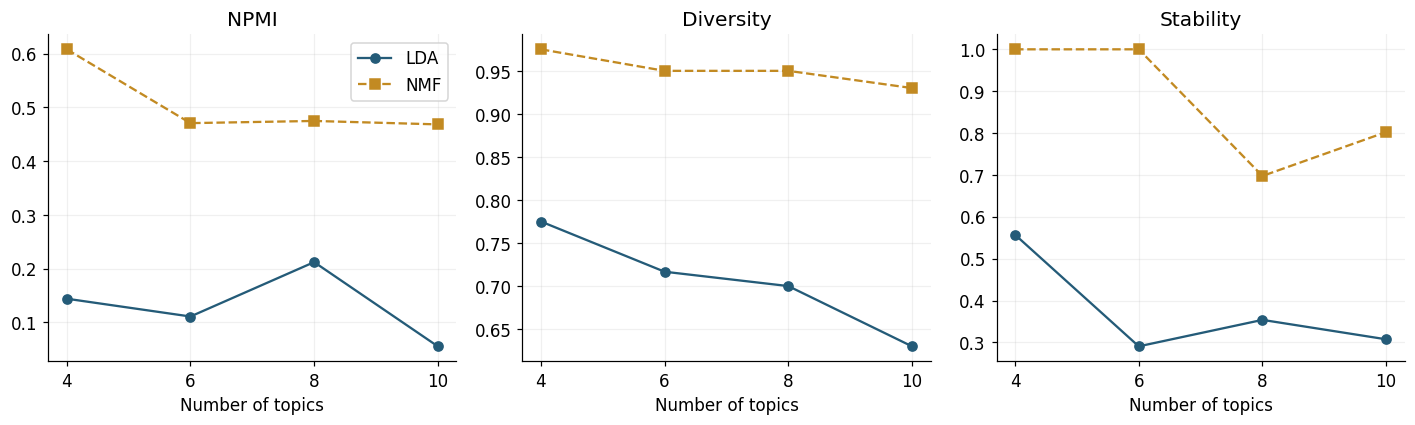

In [ ]:
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,metric in zip(axes,['npmi','diversity','stability']):
    for method,style,color in [('LDA','o-',COLORS[0]),('NMF','s--',COLORS[1])]:
        q=topic_selection[topic_selection.method.eq(method)].sort_values('topics')
        ax.plot(q.topics,q[metric],style,label=method,color=color)
    ax.set(title=metric.upper() if metric=='npmi' else metric.title(),xlabel='Number of topics');ax.set_xticks([4,6,8,10])
axes[0].legend();finish('03_topic_selection')

## 5. Final topics, representative tweets and scores — Q1.7; Q1.9–10
The final model uses the selected method and topic count, fitted on at most 20,000 unique cleaned messages. All eligible English sample tweets are transformed. A zero vocabulary/zero-weight row is unassigned, never forced into topic 0. Normalised NMF weights are **scores, not calibrated probabilities**; LDA scores are model-estimated topic proportions.

Representative examples must contain at least eight cleaned tokens and are ranked by cosine similarity between their representation and the assigned topic's term vector, while removing identical cleaned texts. This avoids choosing a weak document just because its normalised score is 1.0, and avoids isolated emoji/hashtag examples. The topic labels and interpretations are grounded in the fitted keywords and inspected examples; they describe observed clusters, including promotions if those dominate.

In [ ]:
fit_docs=topic_docs.sample(n=min(20000,len(topic_docs)),random_state=SEED)
final_vectorizer=CountVectorizer(max_features=6000,min_df=5,max_df=.65,ngram_range=(1,2))
fit_counts=final_vectorizer.fit_transform(fit_docs.cleaned_text)
final_tfidf=TfidfTransformer(sublinear_tf=True)
fit_input=fit_counts if SELECTED_METHOD=='LDA' else final_tfidf.fit_transform(fit_counts)
final_model=make_topic_model(SELECTED_METHOD,SELECTED_K,SEED)
final_model.fit(fit_input)
all_counts=final_vectorizer.transform(tweets.cleaned_text)
all_input=all_counts if SELECTED_METHOD=='LDA' else final_tfidf.transform(all_counts)
raw_scores=final_model.transform(all_input)
row_sum=raw_scores.sum(axis=1)
scores=np.divide(raw_scores,row_sum[:,None],out=np.zeros_like(raw_scores),where=row_sum[:,None]>1e-12)
supported=(all_counts.getnnz(axis=1)>0)&(row_sum>1e-12)&tweets.topic_token_count.ge(3).to_numpy()
tweets['assigned_topic']=np.where(supported,scores.argmax(axis=1),-1)
tweets['topic_score']=np.where(supported,scores.max(axis=1),np.nan)
tweets['assignment_status']=np.where(supported,'Assigned','Unassigned: short or no vocabulary/weight')
final_terms=final_vectorizer.get_feature_names_out()
document_topic_similarity=cosine_similarity(all_input,final_model.components_)
tweets['topic_cosine_similarity']=np.where(supported,document_topic_similarity[np.arange(len(tweets)),scores.argmax(axis=1)],np.nan)
profiles=[];representatives=[]
for k,ids in enumerate(top_ids(final_model,12)):
    profiles.append({'topic':k,'keywords':', '.join(final_terms[ids])})
    subset=tweets[tweets.assigned_topic.eq(k)&tweets.topic_token_count.ge(8)].drop_duplicates('cleaned_text')
    chosen=subset.sort_values('topic_cosine_similarity',ascending=False).head(3)
    if len(chosen)<3:
        chosen=tweets[tweets.assigned_topic.eq(k)].drop_duplicates('cleaned_text').sort_values('topic_cosine_similarity',ascending=False).head(3)
    for _,r in chosen.iterrows():representatives.append({'topic':k,'source_row':r.source_row,'date':str(r.timestamp),'score':r.topic_score,'cosine_similarity':r.topic_cosine_similarity,'tweet':r.text})
profiles=pd.DataFrame(profiles);representatives=pd.DataFrame(representatives)
display(profiles);display(representatives)
profiles.to_csv(OUT/'final_topic_keywords.csv',index=False)
representatives.to_csv(OUT/'representative_tweets.csv',index=False)

,topic,keywords
0,0,"crypto, cryptocurrency, blockchain, crypto cryptocurrency, ethereum, cryptonews, trading, altcoin, cryptocurrency ethereum, binance, eth..."
1,1,"join playing, coinhuntworld awesome, playing coinhuntworld, awesome cryptocurrency, coinhuntworld, vault location, vault, location join,..."
2,2,"lightning, free lightning, lightning sats, sats, unlock, faucet, lightningnetwork, lightningnetwork boltcoiner, boltcoiner, free, zesty ..."
3,3,"project, airdrop, bsc, good, great, future, team, airdrops, best, good project, hope, airdrop airdrops"
4,4,"buy, price, time, just, market, long, bullish, binance, sell, target, signals, stop"
5,5,"eth, nft, bnb, nfts, ethereum, doge, nftcommunity, ada, metaverse, xrp, opensea, crypto"


,topic,source_row,date,score,cosine_similarity,tweet
0,0,4344602,2025-10-11 00:24:09+00:00,1.000000,0.698610,The Crypto Prophecies (TCP) went down 11.5 percent in the last 1 minutes on https://t.co/rgEAV9yjP2. #TCP #crypto #bitcoin #cryptocurre...
1,0,3350843,2025-05-23 23:59:41+00:00,0.992239,0.674324,New Zealand Police investigate allegedly fraudulent crypto platform Quwiex #crypto #bitcoin #cryptocurrency #btc #ethereum #blockchain #...
2,0,3891971,2025-07-15 07:22:27+00:00,1.000000,0.673095,PotCoin (POT) went down 12.1 percent in the last 1 minutes on https://t.co/rgEAV9yjP2. #POT #crypto #bitcoin #cryptocurrency #btc #ethe...
3,1,3477315,2025-06-02 17:51:50+00:00,1.000000,0.983164,"CapricornBae found #bitcoin in a User vault at this location! Join me playing #coinhuntworld, It's awesome! https://t.co/lVDuwzZU8Z #cry..."
4,1,1013893,2025-08-14 18:52:34+00:00,1.000000,0.983164,"AlterEgo found #bitcoin in a User vault at this location! Join me playing #coinhuntworld, It's awesome! https://t.co/lWa8DzS7Qf #cryptoc..."
5,1,2107367,2026-01-12 01:45:16+00:00,1.000000,0.983164,"Bearsquid86 found #bitcoin in a User vault at this location! Join me playing #coinhuntworld, It's awesome! https://t.co/2mW2uAIwxE #cryp..."
6,2,3740785,2025-06-24 18:41:38+00:00,1.000000,0.917935,This zesty faucet from @_bitcoiner is making me tweet this to claim my free Lightning sats. ⚡\n\n@boltcoiner unlock me 2c60bca2-995f-48c...
7,2,2817034,2025-04-13 19:36:20+00:00,1.000000,0.917935,This zesty faucet from @_bitcoiner is making me tweet this to claim my free Lightning sats. ⚡\n\n@boltcoiner unlock me b2809b85-f457-47f...
8,2,4373392,2025-10-09 21:02:18+00:00,1.000000,0.917935,This zesty faucet from @_bitcoiner is making me tweet this to claim my free Lightning sats. ⚡\n\n@boltcoiner unlock me c4f59e02-6b37-4ff...
9,3,1761588,2025-11-19 17:29:45+00:00,0.932981,0.569274,"@AirdropStario Great giveaway project A very good project i thik it is one of the best project in the world, \n\n@mcmimi0 \n\n@mcjahidul..."


### 5.1 Evidence-based topic interpretation
The accompanying topic interpretation file is keyed by the method, topic count and fitted keyword lists. The check below prevents stale labels being applied to a different model. If a later rerun changes topics, review and update the interpretation file before submitting.

In [ ]:
signature=hashlib.sha256(profiles.to_json(orient='records').encode()).hexdigest()
interpretation_path=DATA/'topic_interpretations.json'
if interpretation_path.exists():
    interpretation=json.loads(interpretation_path.read_text())
    if interpretation.get('signature')!=signature:raise ValueError('Topic keywords changed. Review topic_interpretations.json before using old labels.')
    topic_text={int(k):v for k,v in interpretation['topics'].items()}
else:
    raise FileNotFoundError('Reviewed topic_interpretations.json is required; do not substitute placeholders.')
assert set(topic_text) == set(range(SELECTED_K)), 'Every topic needs an interpretation.'
assert all(len(v['interpretation'].split()) >= 20 and 'pending' not in v['interpretation'].lower() for v in topic_text.values())
profiles['label']=profiles.topic.map(lambda k:topic_text[k]['label'])
profiles['interpretation']=profiles.topic.map(lambda k:topic_text[k]['interpretation'])
tweets['topic_label']=tweets.assigned_topic.map(profiles.set_index('topic').label).fillna('Unassigned')
counts=tweets[tweets.assigned_topic.ge(0)].groupby('assigned_topic').sampling_weight.sum()
profiles['weighted_share_assigned']=profiles.topic.map(counts/counts.sum())
profiles['sampled_tweets']=profiles.topic.map(tweets.assigned_topic.value_counts()).fillna(0).astype(int)
display(profiles[['topic','label','sampled_tweets','weighted_share_assigned']])
profiles.to_csv(OUT/'topic_summary.csv',index=False)
say(f"**{supported.sum():,}/{len(tweets):,}** English sample tweets receive supported assignments "
    f"({supported.mean():.1%}). The remainder is explicitly unassigned. "
    "Weighted shares estimate the composition of the structurally valid, English-eligible source sample; they do not measure all Twitter.")

,topic,label,sampled_tweets,weighted_share_assigned
0,0,Crypto news and altcoin alerts,3564,0.146524
1,1,Coin Hunt World game posts,369,0.016140
2,2,Lightning reward-faucet claims,590,0.023813
3,3,Airdrops and project promotion,2387,0.119976
4,4,Market outlook and trading signals,11754,0.474655
5,5,NFTs and altcoin communities,5086,0.218892


**23,750/24,187** English sample tweets receive supported assignments (98.2%). The remainder is explicitly unassigned. Weighted shares estimate the composition of the structurally valid, English-eligible source sample; they do not measure all Twitter.

### 5.2 Full topic interpretations and representative tweets

In [ ]:
# Render paragraphs instead of a width-limited DataFrame so no interpretation is truncated.
from IPython.display import HTML
for row in profiles.itertuples():
    examples = representatives.loc[representatives.topic.eq(row.topic)]
    body = f'<h4>Topic {row.topic}: {html.escape(row.label)}</h4>'
    body += f'<p><b>Keywords:</b> {html.escape(row.keywords)}</p>'
    body += f'<p><b>Interpretation:</b> {html.escape(row.interpretation)}</p>'
    body += '<p><b>Representative tweets:</b></p><ol>'
    for example in examples.itertuples():
        body += f'<li><p>{html.escape(example.tweet)}</p><small>Source row {example.source_row}; {html.escape(example.date)}</small></li>'
    body += '</ol>'
    display(HTML('<div style="white-space:normal;overflow-wrap:anywhere;max-width:100%;">'+body+'</div>'))
say('All six JSON entries contain reviewed, substantive interpretations. The keyword signature matches the fitted topics; no placeholder interpretation is accepted.')

All six JSON entries contain reviewed, substantive interpretations. The keyword signature matches the fitted topics; no placeholder interpretation is accepted.

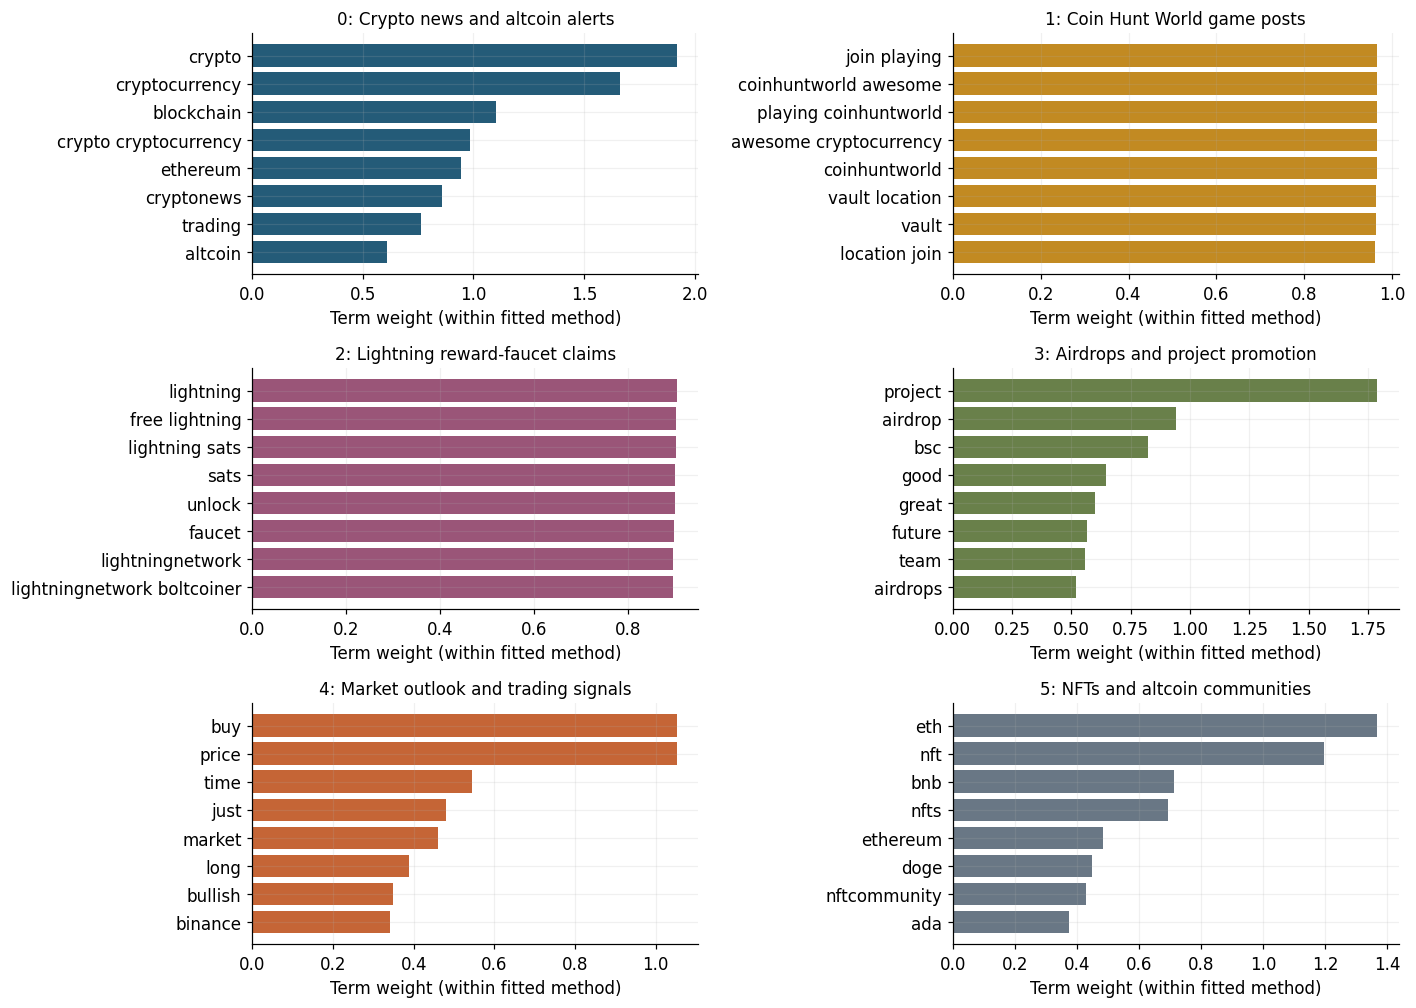

In [ ]:
rows=int(np.ceil(SELECTED_K/2));fig,axes=plt.subplots(rows,2,figsize=(13,3.1*rows),squeeze=False)
for k,ax in enumerate(axes.flat):
    if k>=SELECTED_K:ax.axis('off');continue
    ids=np.argsort(final_model.components_[k])[-8:]
    ax.barh(final_terms[ids],final_model.components_[k,ids],color=COLORS[k%len(COLORS)])
    ax.set_title(f"{k}: {topic_text[k]['label']}",fontsize=11);ax.set_xlabel('Term weight (within fitted method)')
finish('04_final_topic_terms')

### 5.3 Topic word clouds — Q1.9
Font size represents relative **NMF component weight within each topic**, not tweet count or sentiment. Each cloud is scaled independently; compare words within a cloud, not their font sizes across clouds. The exact top-term bar charts above remain the quantitative reference.

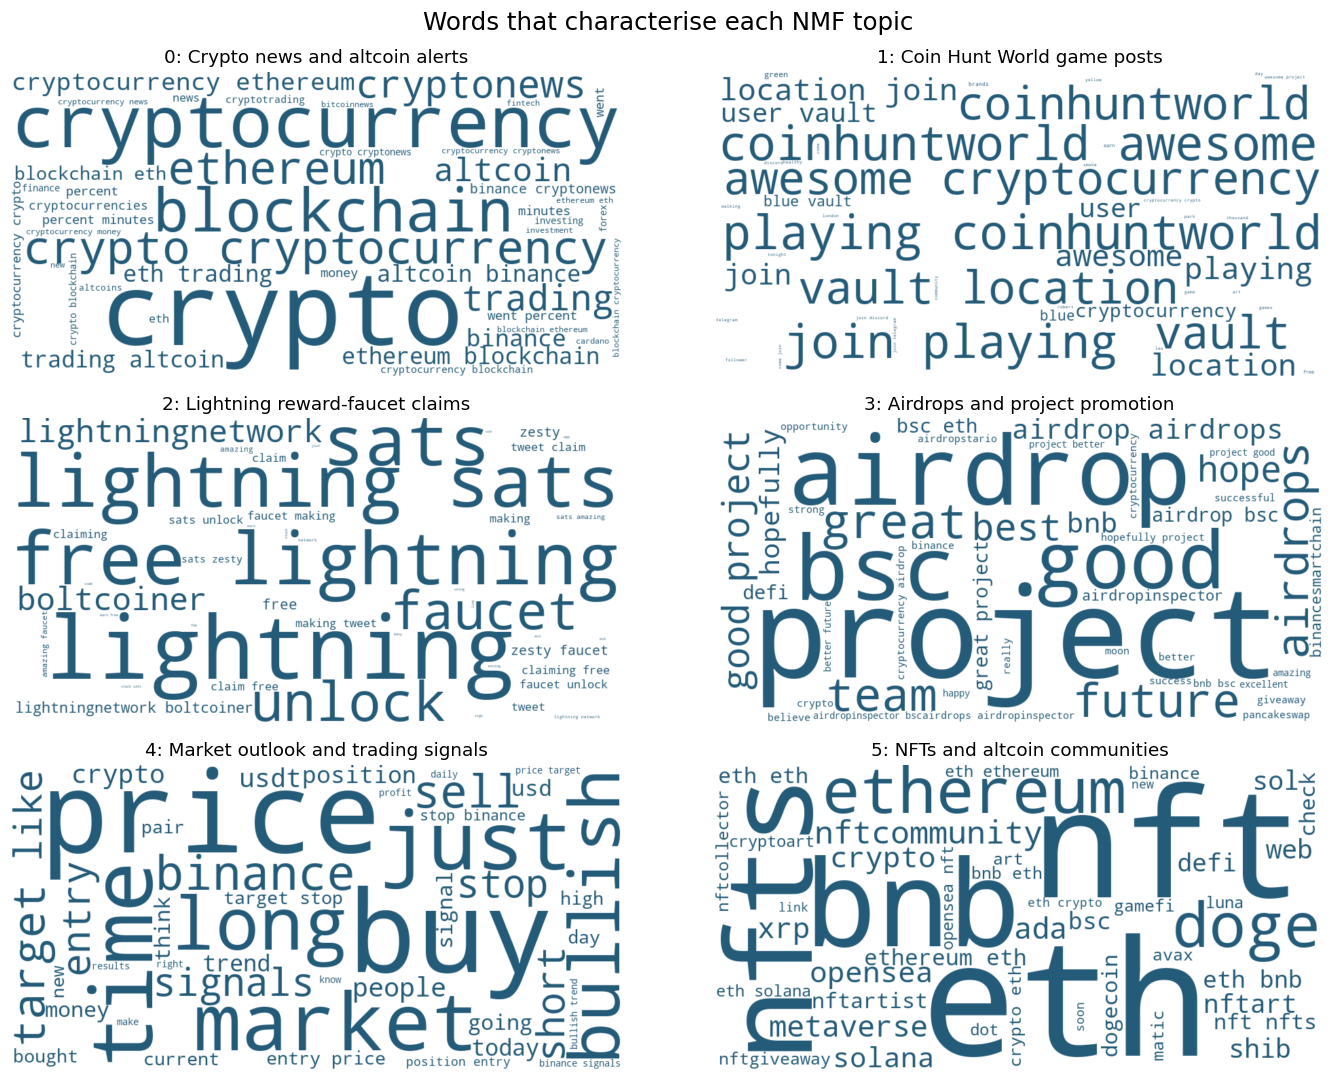

In [ ]:
from wordcloud import WordCloud
import textwrap
fig,axes = plt.subplots(3,2,figsize=(13,10))
for k,axis in enumerate(axes.flat):
    weights = {final_terms[j]:float(final_model.components_[k,j])
               for j in np.argsort(final_model.components_[k])[-45:] if final_model.components_[k,j]>0}
    cloud = WordCloud(width=900,height=450,background_color='white',max_words=45,
                      random_state=SEED,collocations=False,color_func=lambda *args, **kwargs: '#245B78').generate_from_frequencies(weights)
    axis.imshow(cloud,interpolation='bilinear');axis.axis('off')
    axis.set_title(textwrap.fill(f"{k}: {topic_text[k]['label']}",45),fontsize=12)
fig.suptitle('Words that characterise each NMF topic',fontsize=16)
finish('10_topic_wordclouds')

### 5.4 Topic-similarity map — Q1.9
Cosine similarity compares the six fitted topic–term weight vectors. The map uses classical multidimensional scaling of Euclidean distances between L2-normalised vectors (distance = √(2 × (1 − cosine))). Nearer points have more similar vocabulary, subject to two-dimensional projection error. Axes are abstract coordinates, not sentiment or time; the heatmap reports the exact similarities. Bubble area encodes weighted share among assigned tweets.

In [ ]:
# Compute exact similarities, then obtain a deterministic two-dimensional projection.
topic_vectors = final_model.components_ / np.linalg.norm(final_model.components_,axis=1,keepdims=True)
topic_similarity = np.clip(topic_vectors @ topic_vectors.T,-1,1)
np.fill_diagonal(topic_similarity,1.)
distance_squared = np.maximum(2*(1-topic_similarity),0)
centering = np.eye(SELECTED_K)-np.ones((SELECTED_K,SELECTED_K))/SELECTED_K
gram = -.5*centering @ distance_squared @ centering
eigenvalues,eigenvectors = np.linalg.eigh(gram)
ranked = np.argsort(eigenvalues)[::-1]
coordinates = eigenvectors[:,ranked[:2]] * np.sqrt(np.maximum(eigenvalues[ranked[:2]],0))
# Fix eigenvector sign ambiguity so equivalent runs use the same orientation.
for axis in range(2):
    anchor = np.argmax(np.abs(coordinates[:,axis]))
    if coordinates[anchor,axis]<0:coordinates[:,axis]*=-1
projection_share = np.maximum(eigenvalues[ranked[:2]],0).sum()/np.maximum(eigenvalues,0).sum()
similarity_frame = pd.DataFrame(topic_similarity,index=range(SELECTED_K),columns=range(SELECTED_K))
similarity_frame.to_csv(OUT/'topic_cosine_similarity.csv',index_label='topic')
pd.DataFrame({'topic':profiles.topic,'label':profiles.label,'map_x':coordinates[:,0],
              'map_y':coordinates[:,1],'weighted_share':profiles.weighted_share_assigned}).to_csv(OUT/'topic_map_coordinates.csv',index=False)

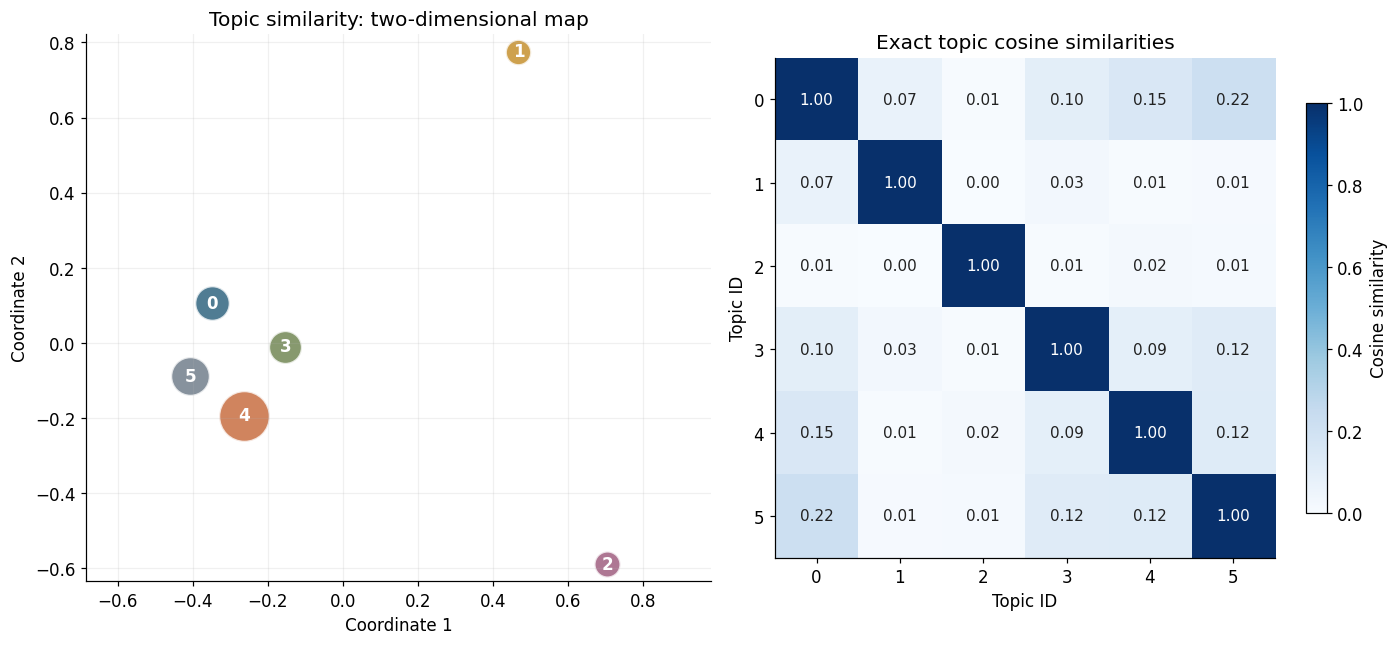

,topic,label
0,0,Crypto news and altcoin alerts
1,1,Coin Hunt World game posts
2,2,Lightning reward-faucet claims
3,3,Airdrops and project promotion
4,4,Market outlook and trading signals
5,5,NFTs and altcoin communities


The closest topic pair is **0: Crypto news and altcoin alerts** and **5: NFTs and altcoin communities**, with cosine similarity **0.218**. The two map dimensions retain **44.8%** of positive eigenvalue mass, so use the exact heatmap when interpreting distances. Topic overlap describes vocabulary, not causal relationships.

In [ ]:
fig,axes = plt.subplots(1,2,figsize=(13,6))
for k in range(SELECTED_K):
    axes[0].scatter(*coordinates[k],s=250+1800*profiles.iloc[k].weighted_share_assigned,
                    color=COLORS[k],alpha=.8,edgecolor='white',linewidth=1.5)
    axes[0].annotate(str(k),coordinates[k],ha='center',va='center',weight='bold',color='white')
axes[0].set(title='Topic similarity: two-dimensional map',xlabel='Coordinate 1',ylabel='Coordinate 2')
axes[0].margins(.25);axes[0].set_aspect('equal',adjustable='datalim')
im=axes[1].imshow(topic_similarity,cmap='Blues',vmin=0,vmax=1)
axes[1].grid(False);axes[1].set(xticks=range(SELECTED_K),yticks=range(SELECTED_K),xlabel='Topic ID',ylabel='Topic ID',title='Exact topic cosine similarities')
for a in range(SELECTED_K):
    for b in range(SELECTED_K):
        axes[1].text(b,a,f'{topic_similarity[a,b]:.2f}',ha='center',va='center',color='white' if topic_similarity[a,b]>.6 else '#222222',fontsize=10)
fig.colorbar(im,ax=axes[1],shrink=.75,label='Cosine similarity')
finish('11_topic_similarity_map')
display(profiles[['topic','label']])
pair_matrix=topic_similarity.copy();np.fill_diagonal(pair_matrix,-np.inf)
a,b=np.unravel_index(np.argmax(pair_matrix),pair_matrix.shape)
say(f"The closest topic pair is **{a}: {topic_text[a]['label']}** and **{b}: {topic_text[b]['label']}**, with cosine similarity **{topic_similarity[a,b]:.3f}**. "
    f"The two map dimensions retain **{projection_share:.1%}** of positive eigenvalue mass, so use the exact heatmap when interpreting distances. Topic overlap describes vocabulary, not causal relationships.")

## 6. How topics change over time — Q1.8–10
Weekly shares use design weights and are conditional on assigned English tweets. The denominator is the sum of weights of assigned tweets within that week. Unassigned records are excluded from that denominator and their coverage is shown separately. Calendar gaps are preserved; no missing week is interpreted as zero discussion. Partial first/last weeks are labelled in the interpretation. Temporal changes show association and dataset composition, not causes or verified external events.

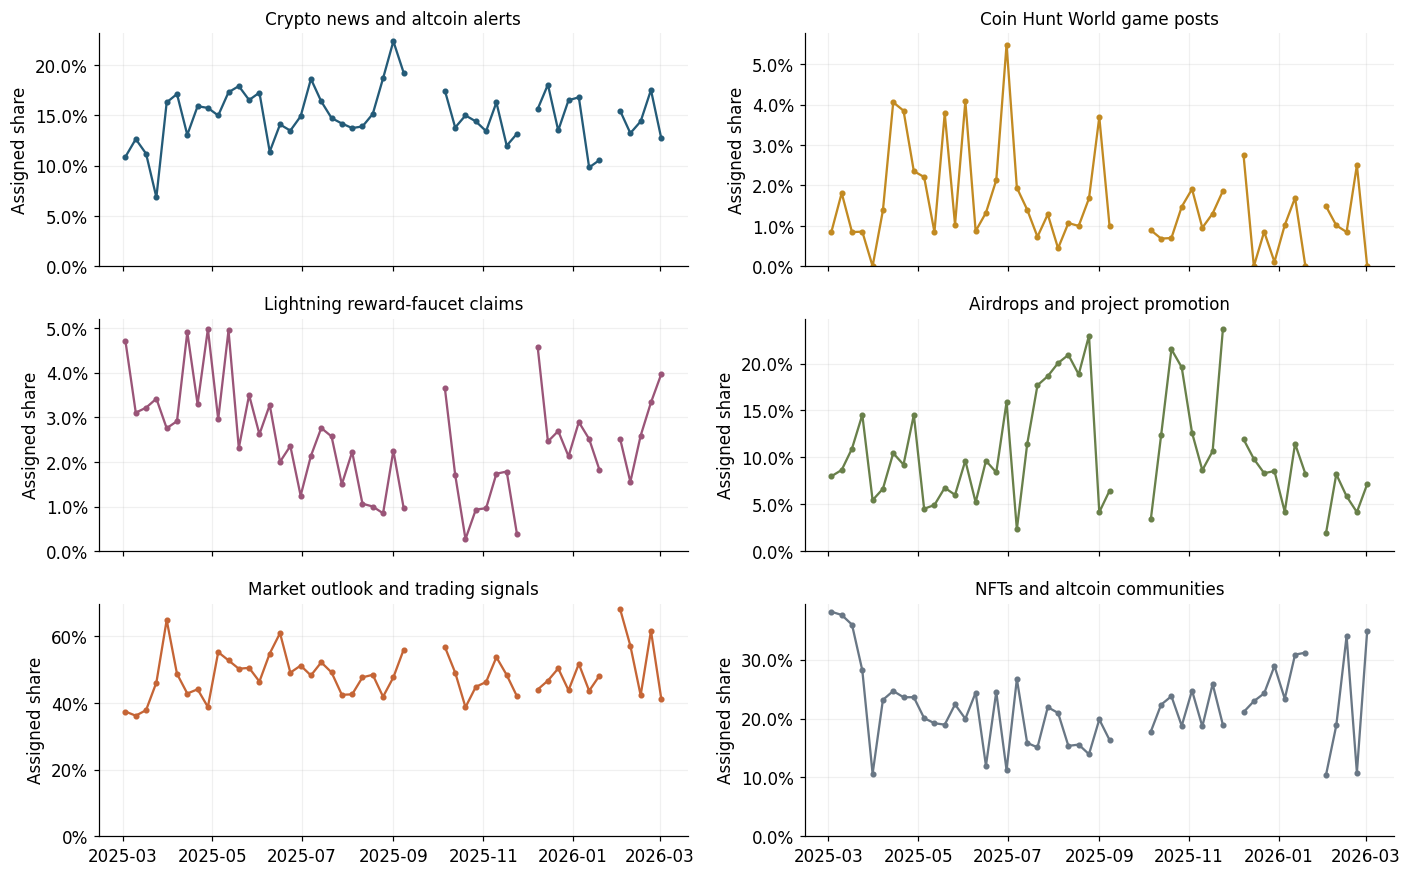

Each panel has its own vertical scale to reveal within-topic changes. Compare percentages, not line heights across panels; absent weeks are gaps.

,topic,label,first_week_share,last_week_share,change_percentage_points,peak_week,peak_share,largest_week_change_pp
4,4,Market outlook and trading signals,0.374324,0.412698,3.837481,2026-02-02,0.682384,-20.396825
0,0,Crypto news and altcoin alerts,0.108704,0.126984,1.827967,2025-09-01,0.223373,9.430778
2,2,Lightning reward-faucet claims,0.047053,0.039683,-0.737044,2025-04-28,0.049790,-2.635251
3,3,Airdrops and project promotion,0.079870,0.071429,-0.844151,2025-11-24,0.237018,-18.809557
1,1,Coin Hunt World game posts,0.008506,0.000000,-0.850590,2025-06-30,0.054889,-3.546860
5,5,NFTs and altcoin communities,0.381543,0.349206,-3.233663,2025-03-03,0.381543,24.087302


**Market outlook and trading signals:** assigned share moves from 37.4% to 41.3% (+3.8 percentage points), peaking at 68.2% in the week beginning 2026-02-02. The largest consecutive-week change is -20.4 points.

**Crypto news and altcoin alerts:** assigned share moves from 10.9% to 12.7% (+1.8 percentage points), peaking at 22.3% in the week beginning 2025-09-01. The largest consecutive-week change is +9.4 points.

**Lightning reward-faucet claims:** assigned share moves from 4.7% to 4.0% (-0.7 percentage points), peaking at 5.0% in the week beginning 2025-04-28. The largest consecutive-week change is -2.6 points.

**Airdrops and project promotion:** assigned share moves from 8.0% to 7.1% (-0.8 percentage points), peaking at 23.7% in the week beginning 2025-11-24. The largest consecutive-week change is -18.8 points.

**Coin Hunt World game posts:** assigned share moves from 0.9% to 0.0% (-0.9 percentage points), peaking at 5.5% in the week beginning 2025-06-30. The largest consecutive-week change is -3.5 points.

**NFTs and altcoin communities:** assigned share moves from 38.2% to 34.9% (-3.2 percentage points), peaking at 38.2% in the week beginning 2025-03-03. The largest consecutive-week change is +24.1 points.

First/last weeks may be partial. Changes can reflect sampling, language classification, promotional repetition and source coverage; they cannot be attributed to an external event without independent evidence.

In [ ]:
tweets['week']=tweets.day.dt.tz_localize(None).dt.to_period('W-SUN').dt.start_time
assigned=tweets[tweets.assigned_topic.ge(0)]
weekly=assigned.pivot_table(index='week',columns='assigned_topic',values='sampling_weight',aggfunc='sum',fill_value=0)
weekly=weekly.reindex(columns=range(SELECTED_K),fill_value=0)
weekly=weekly.reindex(pd.date_range(weekly.index.min(),weekly.index.max(),freq='7D'))
weekly.index.name='week'
weekly_share=weekly.div(weekly.sum(axis=1),axis=0)
coverage=tweets.groupby('week').apply(lambda g:np.average(g.assigned_topic.ge(0),weights=g.sampling_weight),include_groups=False)
fig,axes=plt.subplots(int(np.ceil(SELECTED_K/2)),2,figsize=(13,2.7*int(np.ceil(SELECTED_K/2))),sharex=True,squeeze=False)
for k,ax in enumerate(axes.flat):
    if k>=SELECTED_K:ax.axis('off');continue
    ax.plot(weekly_share.index,weekly_share[k],color=COLORS[k%len(COLORS)],marker='.',linewidth=1.5)
    ax.set_title(topic_text[k]['label'],fontsize=11);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_ylim(bottom=0)
    ax.set_ylabel('Assigned share')
finish('05_weekly_topic_shares')
say('Each panel has its own vertical scale to reveal within-topic changes. Compare percentages, not line heights across panels; absent weeks are gaps.')
weekly_share.rename(columns=profiles.set_index('topic').label.to_dict()).to_csv(OUT/'weekly_topic_shares.csv')
coverage.rename('weighted_assigned_coverage').to_csv(OUT/'weekly_assignment_coverage.csv')
changes=[]
for k in range(SELECTED_K):
    s=weekly_share[k].dropna();delta=weekly_share[k].diff().dropna();peak=s.idxmax()
    changes.append({'topic':k,'label':topic_text[k]['label'],'first_week_share':s.iloc[0],
                    'last_week_share':s.iloc[-1],'change_percentage_points':100*(s.iloc[-1]-s.iloc[0]),
                    'peak_week':str(peak.date()),'peak_share':s.max(),
                    'largest_week_change_pp':100*delta.loc[delta.abs().idxmax()]})
topic_changes=pd.DataFrame(changes).sort_values('change_percentage_points',ascending=False)
display(topic_changes);topic_changes.to_csv(OUT/'topic_change_summary.csv',index=False)
for r in topic_changes.itertuples():
    say(f"**{r.label}:** assigned share moves from {r.first_week_share:.1%} to {r.last_week_share:.1%} "
        f"({r.change_percentage_points:+.1f} percentage points), peaking at {r.peak_share:.1%} in the week beginning {r.peak_week}. "
        f"The largest consecutive-week change is {r.largest_week_change_pp:+.1f} points.")
say('First/last weeks may be partial. Changes can reflect sampling, language classification, promotional repetition and source coverage; they cannot be attributed to an external event without independent evidence.')
assignment_cols=['source_row','timestamp','text','cleaned_text','language','language_probability','assigned_topic','topic_label','topic_score','assignment_status','sampling_weight']
tweets[assignment_cols].to_csv(OUT/'topic_assignments.csv',index=False)
assert len(pd.read_csv(OUT/'topic_assignments.csv'))==len(tweets)

## 7. Sentiment scores and distributions — Q2.2–3; Q2.8
VADER provides a compound polarity score in [−1,+1]. We classify **positive ≥ +0.05**, **negative ≤ −0.05**, otherwise **neutral**, following the author's documented thresholds. These are polarity classes, not forecasts of price direction. The target for human labelling is the **overall emotional/evaluative tone of the text**, including quoted claims as written; crypto bullishness and general emotional tone may disagree, and this distinction limits market interpretation.

Unmodified VADER avoids hand-picked crypto word values. It can miss sarcasm, slang, target-specific opinion and mixed sentiment. A score of zero means no detected net valence; it is not proof of true neutrality. Source: [Hutto & Gilbert, VADER](https://github.com/cjhutto/vaderSentiment).

Unmodified VADER remains the baseline throughout. The next section adds a frozen transformer; no lexicon entries or thresholds are adjusted against the 60 review labels.

,sampled_tweets,weighted_records,weighted_share
sentiment_label,,,
Negative,4033,6.243322e+05,0.165007
Neutral,7049,1.040713e+06,0.275054
Positive,13105,2.118623e+06,0.559939


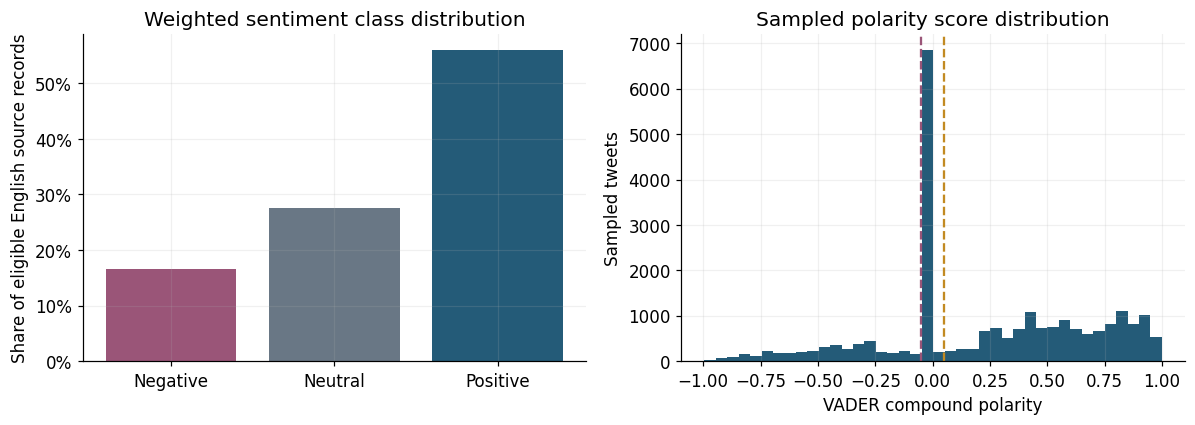

The largest weighted model-labelled class is **Positive** (56.0%). This is a model output, not an accuracy claim; human validation follows.

In [ ]:
analyser=SentimentIntensityAnalyzer()
sentiment_scores=pd.DataFrame([analyser.polarity_scores(t) for t in tweets.sentiment_text],index=tweets.index)
tweets['polarity']=sentiment_scores.compound
tweets['sentiment_label']=np.select([tweets.polarity.ge(.05),tweets.polarity.le(-.05)],['Positive','Negative'],default='Neutral')
sentiment_summary=tweets.groupby('sentiment_label').agg(sampled_tweets=('source_row','size'),weighted_records=('sampling_weight','sum'))
sentiment_summary['weighted_share']=sentiment_summary.weighted_records/sentiment_summary.weighted_records.sum()
display(sentiment_summary)
fig,ax=plt.subplots(1,2,figsize=(11,4))
order=['Negative','Neutral','Positive']
ax[0].bar(order,sentiment_summary.reindex(order).weighted_share,color=[COLORS[2],COLORS[5],COLORS[0]])
ax[0].set(title='Weighted sentiment class distribution',ylabel='Share of eligible English source records');ax[0].yaxis.set_major_formatter(PercentFormatter(1))
ax[1].hist(tweets.polarity,bins=40,color=COLORS[0]);ax[1].axvline(-.05,color=COLORS[2],linestyle='--');ax[1].axvline(.05,color=COLORS[1],linestyle='--')
ax[1].set(title='Sampled polarity score distribution',xlabel='VADER compound polarity',ylabel='Sampled tweets')
finish('06_sentiment_distribution')
tweets[['source_row','timestamp','text','sentiment_text','polarity','sentiment_label','sampling_weight']].to_csv(OUT/'sentiment_tweet_scores.csv',index=False)
sentiment_summary.to_csv(OUT/'sentiment_distribution.csv')
say(f"The largest weighted model-labelled class is **{sentiment_summary.weighted_share.idxmax()}** "
    f"({sentiment_summary.weighted_share.max():.1%}). This is a model output, not an accuracy claim; human validation follows.")
# Preserve original baseline columns for a controlled comparison.
tweets['vader_polarity']=tweets.polarity
tweets['vader_label']=tweets.sentiment_label

### 7.1 Twitter RoBERTa: a second, frozen sentiment model
[CardiffNLP Twitter RoBERTa](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest) was trained on Twitter text and fine-tuned on TweetEval. Its Negative/Neutral/Positive categories fit the human tone labels. It is a social-media model, **not a crypto-specific model**. Domain mismatch, sarcasm and asset-target ambiguity still require empirical evaluation.

We pin revision `3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7`, use the published class order, and never fine-tune on these reviews. Preserve emoji, case and hashtags while standardising user names and URLs. Polarity is P(Positive) − P(Negative); labels use the largest probability. These scores share VADER's −1 to +1 range but are not calibrated equivalents. Long texts are truncated at 512 tokens and counted. Cached probabilities are checked against original text fingerprints; rebuilding requires PyTorch, Transformers and public model weights. Tweets are processed locally, not sent to a hosted inference API.

In [ ]:
"""Frozen Twitter RoBERTa inference; cached by IDs, text, preprocessing and revision."""
from pathlib import Path
import hashlib, html, json, re, time
import numpy as np
import pandas as pd

MODEL_ID = 'cardiffnlp/twitter-roberta-base-sentiment-latest'
MODEL_REVISION = '3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7'
MAX_TOKENS = 512
PREPROCESS_VERSION = 'html-url-user-whitespace-v1'

def transformer_text(text):
    # Preserve casing, hashtags, negation and emoji; standardise links and users.
    text = html.unescape(str(text)).replace('\\n', ' ')
    text = re.sub(r'https?://\S+|www\.\S+', 'http', text)
    text = re.sub(r'@\w+', '@user', text)
    return re.sub(r'\s+', ' ', text).strip()

In [ ]:
def score_transformer(frame, data_dir, rebuild=False):
    data_dir = Path(data_dir)
    cache = data_dir / 'twitter_roberta_scores.parquet'
    metadata_path = data_dir / 'twitter_roberta_provenance.json'
    rows = frame[['source_row', 'text']].copy().sort_values('source_row')
    rows['text_sha256'] = rows.text.map(lambda t: hashlib.sha256(t.encode()).hexdigest())
    digest = hashlib.sha256(rows[['source_row','text_sha256']].to_json(orient='records').encode()).hexdigest()
    settings = dict(model=MODEL_ID, revision=MODEL_REVISION, max_tokens=MAX_TOKENS,
                    preprocessing=PREPROCESS_VERSION, input_sha256=digest)
    if not rebuild and cache.exists() and metadata_path.exists():
        metadata = json.loads(metadata_path.read_text())
        if all(metadata.get(k) == v for k,v in settings.items()):
            cached = pd.read_parquet(cache)
            assert cached.source_row.is_unique and set(cached.source_row) == set(rows.source_row)
            expected_hashes = rows.set_index('source_row').text_sha256
            assert cached.text_sha256.eq(cached.source_row.map(expected_hashes)).all()
            probs = cached[['roberta_negative','roberta_neutral','roberta_positive']].to_numpy()
            assert np.isfinite(probs).all() and np.allclose(probs.sum(axis=1), 1, atol=1e-5)
            return cached, metadata

    # Heavy dependencies and public weights are needed only when rebuilding the cache.
    import os, torch, transformers
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    os.environ.setdefault('TOKENIZERS_PARALLELISM','false')
    torch.manual_seed(6808)
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    model.to(device).eval()
    labels = {int(k): str(v).lower() for k,v in model.config.id2label.items()}
    assert labels == {0:'negative',1:'neutral',2:'positive'}, labels
    texts = rows.text.map(transformer_text).tolist()
    lengths = np.array([len(tokenizer.encode(t, truncation=False)) for t in texts])
    # Sort by token length to reduce padding; restore original row order afterwards.
    processing_order = np.argsort(lengths, kind='stable')
    probabilities = np.empty((len(rows),3),dtype=np.float32)
    batch_size = 16
    start = time.time()
    for offset in range(0,len(rows),batch_size):
        ids = processing_order[offset:offset+batch_size]
        batch = tokenizer([texts[i] for i in ids],padding=True,truncation=True,
                          max_length=MAX_TOKENS,return_tensors='pt').to(device)
        with torch.inference_mode():
            probabilities[ids] = model(**batch).logits.softmax(dim=-1).cpu().numpy()
        if offset % (batch_size*64) == 0:
            print(f'Twitter RoBERTa: {min(offset+batch_size,len(rows)):,}/{len(rows):,} tweets; {time.time()-start:.0f}s ({device})',flush=True)
    result = rows[['source_row','text_sha256']].copy()
    result[['roberta_negative','roberta_neutral','roberta_positive']] = probabilities
    result['roberta_polarity'] = probabilities[:,2] - probabilities[:,0]
    result['roberta_label'] = np.array(['Negative','Neutral','Positive'])[probabilities.argmax(axis=1)]
    result['tokens_before_truncation'] = lengths
    result.to_parquet(cache,index=False)
    metadata = dict(settings, rows=len(rows), truncated_tweets=int((lengths>MAX_TOKENS).sum()),
                    device=device, torch_version=torch.__version__,transformers_version=transformers.__version__,
                    created_utc=pd.Timestamp.now(tz='UTC').isoformat(),
                    score='P(Positive) - P(Negative); class = argmax probability',
                    labels_used_for_training=False)
    metadata_path.write_text(json.dumps(metadata,indent=2))
    return result, metadata

In [ ]:
REBUILD_TRANSFORMER=False
# Dependencies are optional for ordinary cached reruns; install only to rebuild scores.
if REBUILD_TRANSFORMER or not (DATA/'twitter_roberta_scores.parquet').exists():
    subprocess.check_call([sys.executable,'-m','pip','install','torch>=2.6','transformers>=4.48,<5'])
roberta_scores,roberta_provenance=score_transformer(tweets,DATA,rebuild=REBUILD_TRANSFORMER)
tweets=tweets.merge(roberta_scores.drop(columns='text_sha256'),on='source_row',validate='one_to_one')
say(f"Scored **{len(roberta_scores):,} tweets** with the pinned transformer. **{roberta_provenance['truncated_tweets']}** exceeded the 512-token limit. Class probabilities are model outputs, not guarantees of correctness.")
display(pd.Series(roberta_provenance,name='Value').to_frame())
tweets[['source_row','timestamp','text','vader_polarity','vader_label','roberta_polarity','roberta_label',
        'roberta_negative','roberta_neutral','roberta_positive']].to_csv(OUT/'sentiment_model_tweet_scores.csv',index=False)

Scored **24,187 tweets** with the pinned transformer. **0** exceeded the 512-token limit. Class probabilities are model outputs, not guarantees of correctness.

,Value
model,cardiffnlp/twitter-roberta-base-sentiment-latest
revision,3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7
max_tokens,512
preprocessing,html-url-user-whitespace-v1
input_sha256,4485118db2b4588b0aab0167d070a27ee50571b2ba900360fed6762ccf889b62
rows,24187
truncated_tweets,0
device,mps
torch_version,2.14.0
transformers_version,4.57.6


## 8. Independent human sentiment review — Q2.4
**This requirement cannot be replaced by automatically generated labels.** A reproducible random sample of 60 eligible tweets is exported with predictions hidden. The human review file is never overwritten on rerun. A completed file requires at least 50 unique valid labels, a reviewer name/initials, and identifiers/text matching the sampled records. Accuracy is measured on the reviewed sample and does not imply corpus-wide accuracy. This simple random sample evaluates the unweighted modelling sample; date-stratified design weights are not used in the validation accuracy.

Fill `outputs/human_sentiment_labels.csv`:

1. Read the full raw tweet, independently of VADER's prediction.
2. Enter `Positive`, `Negative` or `Neutral` in `human_label`. Positive means approving/optimistic tone; negative means disapproving/pessimistic tone; neutral means factual, balanced or no clear polarity. Do not label a factual price decline negative solely because the price fell.
3. Use `notes` for sarcasm, mixed sentiment, slang, quotation, negation or uncertain target; complete `reviewer`.
4. Save as UTF-8 CSV, retaining row identifiers and text. Rerun this section onward.

Two group members may label independently and reconcile disagreements; that is useful but not mandatory. The code reports confusion, class-level precision/recall/F1 and concrete misclassified examples only after actual human labels are present. Before then, results are explicitly pending.

**Encoding repair:** 27 review texts contained reversible UTF-8/MacRoman encoding damage. Original text was restored and verified against both the source sample and stored SHA-256 fingerprints; all supplied labels, reviewer names and notes were preserved. The edited CSV was backed up separately. The repaired file uses UTF-8 with a byte-order mark for Excel. If you judged a tweet while its emoji were garbled, revisit that judgement using the restored text before submission.

**Review coverage:** supplied labels comprise 29 Positive, 28 Neutral and only 3 Negative tweets. Negative-class results therefore have substantial sampling uncertainty. Some reviewer notes refer specifically to Bitcoin while VADER scores the whole tweet; this target mismatch is a limitation of the comparison.


### 8.1 Check human review identifiers, original text and labels

In [ ]:
review_path=OUT/'human_sentiment_labels.csv'
review_sample=tweets.sample(n=min(60,len(tweets)),random_state=SEED)[['source_row','timestamp','text']].copy()
review_sample['text_sha256']=review_sample.text.map(lambda t:hashlib.sha256(t.encode()).hexdigest())
review_sample['human_label']='';review_sample['reviewer']='';review_sample['notes']=''
if not review_path.exists():review_sample.to_csv(review_path,index=False)
review=pd.read_csv(review_path,keep_default_na=False)
assert review.source_row.is_unique,'Human review contains duplicate source identifiers.'
assert set(review.source_row)<=set(review_sample.source_row),'Review IDs do not match the fixed review sample.'
expected=review_sample.set_index('source_row').text_sha256
assert all(review.text_sha256==review.source_row.map(expected)),'Review text fingerprints changed.'
assert all(review.text.map(lambda t:hashlib.sha256(t.encode()).hexdigest())==review.text_sha256),'Review text was edited.'
review['human_label']=review.human_label.str.strip().str.title()
allowed={'Positive','Negative','Neutral'}
bad=review.human_label.ne('')&~review.human_label.isin(allowed)
assert not bad.any(),'Invalid label: use Positive, Negative or Neutral.'
labelled=review[review.human_label.isin(allowed)&review.reviewer.str.strip().ne('')].copy()

### 8.2 Baseline VADER accuracy and error examples

In [ ]:
validation_complete=len(labelled)>=50
validation_accuracy=None
if validation_complete:
    labelled=labelled.merge(tweets[['source_row','sentiment_label']],on='source_row',validate='one_to_one')
    validation_accuracy=accuracy_score(labelled.human_label,labelled.sentiment_label)
    confusion=pd.DataFrame(confusion_matrix(labelled.human_label,labelled.sentiment_label,labels=order),index=order,columns=order)
    display(confusion)
    report=pd.DataFrame(classification_report(labelled.human_label,labelled.sentiment_label,labels=order,output_dict=True,zero_division=0)).T
    display(report)
    errors=labelled[labelled.human_label.ne(labelled.sentiment_label)]
    display(errors[['text','human_label','sentiment_label','notes']].head(12))
    labelled.to_csv(OUT/'completed_sentiment_validation.csv',index=False)
    report.to_csv(OUT/'sentiment_validation_metrics.csv');errors.to_csv(OUT/'sentiment_validation_errors.csv',index=False)
    say(f"Human-sample accuracy: **{validation_accuracy:.1%}** on **{len(labelled)}** tweets. "
        f"There are **{len(errors)}** disagreements; reviewer notes and examples above identify the observed error types.")
    if len(errors):
        error_patterns=errors.groupby(['human_label','sentiment_label']).size().sort_values(ascending=False)
        display(error_patterns.rename('Errors').to_frame())
        for (actual,predicted),number in error_patterns.head(3).items():
            say(f"Observed confusion: **{actual} → {predicted}**, {number} tweet(s). Inspect the linked example texts and reviewer notes for sarcasm, slang, negation or target ambiguity; these causes cannot be inferred from the confusion count alone.")
        notes=errors.loc[errors.notes.str.strip().ne(''),'notes']
        if len(notes):display(notes.rename('Reviewer explanations').to_frame())
else:
    say(f"**PENDING — {len(labelled)}/60 human reviews completed.** At least 50 valid independent human labels are needed. "
        "No accuracy or empirical misclassification rate can honestly be reported yet. The rest of the analysis runs, but sentiment validity remains unverified.")
validation_status={'completed':validation_complete,'labelled_tweets':len(labelled),'accuracy':validation_accuracy,
                   'requirement':'At least 50 independent human labels (or separately justified sample)'}
(OUT/'human_validation_status.json').write_text(json.dumps(validation_status,indent=2))
display(review[['source_row','text','human_label','reviewer']].head(3))

,Negative,Neutral,Positive
Negative,3,0,0
Neutral,2,15,11
Positive,6,3,20


,precision,recall,f1-score,support
Negative,0.272727,1.000000,0.428571,3.000000
Neutral,0.833333,0.535714,0.652174,28.000000
Positive,0.645161,0.689655,0.666667,29.000000
accuracy,0.633333,0.633333,0.633333,0.633333
macro avg,0.583741,0.741790,0.582471,60.000000
weighted avg,0.714353,0.633333,0.647999,60.000000


,text,human_label,sentiment_label,notes
1,Now all Youtubers are active. Have they been sleeping? #btc #bitcoin breakout,Neutral,Positive,Casual observation about YouTuber activity tied to a breakout; no clear stance expressed.
7,@JrKripto The old ones are outdated.\nTo earn You have to keep up with the new age.\nTomorrow May Be Too Late ...\n\n#Metaverse\n#Blokto...,Positive,Negative,Hype-driven promotional thread urging urgency to buy/follow trending coins.
9,"Today Elon Musk will talk in an event regarding Bitcoin. Pretty simple, if he changes his opinion on Bitcoin and adopts it again, the ra...",Neutral,Positive,"Ambiguous: presents both a bullish and bearish scenario evenhandedly, contingent on Musk's comments."
10,#SHINJA 🥷⚔️🚀🚀 \nDon’t missed #SHINJA 🥷🏿🔥\nBuy Now and Happy later 🥷🏿🔥\n\n#Shibnobi #Crypto #DeFi #BTC #SHIB #Ceek #AVAX #BNB\n#Ethereum ...,Positive,Negative,"Promotional hype telling users to ""Buy Now and Happy later."""
15,"@jpkolk @chriswarkentin Before you drop the dumb ""Bitcoin is crypto"" dialogue. #Bitcoin is free, permissionless, censorship resistant, l...",Positive,Negative,"Passionately defends Bitcoin's properties (permissionless, hard money); celebratory of BTC despite criticizing the word ""crypto."""
16,Current top 10 coins by 1-week market dominance:\n\n1️⃣ $btc\n2️⃣ $eth\n3️⃣ $usdt\n4️⃣ $usdc\n5️⃣ $bnb\n6️⃣ $busd\n7️⃣ $ada\n8️⃣ $xrp\n9...,Neutral,Positive,Ranked list of coins by market dominance; no opinion given.
22,Tomorrow is the monthly close candle. Are the bulls going to push the price for a good close? 🤔 #Bitcoin,Neutral,Positive,Ambiguous: speculative question about whether bulls push price up; no stated opinion.
25,Time: 16/03/2022 5:00 EST 🔈\nSymbol: BTC 🚀\nAlert: Long Entry 🟢 \nLevel: 40310.0 🔍\nTarget: 40919.9 🎯\nStop: 38294.5 ⚠️\nSize (for 10k a...,Neutral,Negative,Trade alert with numeric levels only.
26,I have this recorded for today. Can't wait to watch this 🤣🤣🤣 #btc #bitcoin https://t.co/3GrpUwjRFO,Neutral,Positive,Ambiguous: laughing-emoji reaction to unspecified recorded content; unclear whether mocking or excited.
28,Current #Cardano price Alert: \n\n#ADA $0.4568 USD\n#Bitcoin 2.2734907888286393e-05 BTC\n#Ethereum 0.0002875162074044235 ETH\n\nFollow f...,Neutral,Positive,Automated price alert for Cardano/Bitcoin/Ethereum ratios.


Human-sample accuracy: **63.3%** on **60** tweets. There are **22** disagreements; reviewer notes and examples above identify the observed error types.

Errors
human_label sentiment_label        
Neutral     Positive             11
Positive    Negative              6
            Neutral               3
Neutral     Negative              2

Observed confusion: **Neutral → Positive**, 11 tweet(s). Inspect the linked example texts and reviewer notes for sarcasm, slang, negation or target ambiguity; these causes cannot be inferred from the confusion count alone.

Observed confusion: **Positive → Negative**, 6 tweet(s). Inspect the linked example texts and reviewer notes for sarcasm, slang, negation or target ambiguity; these causes cannot be inferred from the confusion count alone.

Observed confusion: **Positive → Neutral**, 3 tweet(s). Inspect the linked example texts and reviewer notes for sarcasm, slang, negation or target ambiguity; these causes cannot be inferred from the confusion count alone.

,Reviewer explanations
1,Casual observation about YouTuber activity tied to a breakout; no clear stance expressed.
7,Hype-driven promotional thread urging urgency to buy/follow trending coins.
9,"Ambiguous: presents both a bullish and bearish scenario evenhandedly, contingent on Musk's comments."
10,"Promotional hype telling users to ""Buy Now and Happy later."""
15,"Passionately defends Bitcoin's properties (permissionless, hard money); celebratory of BTC despite criticizing the word ""crypto."""
16,Ranked list of coins by market dominance; no opinion given.
22,Ambiguous: speculative question about whether bulls push price up; no stated opinion.
25,Trade alert with numeric levels only.
26,Ambiguous: laughing-emoji reaction to unspecified recorded content; unclear whether mocking or excited.
28,Automated price alert for Cardano/Bitcoin/Ethereum ratios.


,source_row,text,human_label,reviewer
0,47858,grab the opportunity to win upto 0.005 btc per week only at https://t.co/9JmjDEsjGO #cryptocurrency #win #lasvegas… https://t.co/3t8lesGQ7I,Positive,LS Nhlapo
1,48497,Now all Youtubers are active. Have they been sleeping? #btc #bitcoin breakout,Neutral,BN Mbokdo
2,3489523,"Bear market still in tact, rejected the 21 on the daily after 2 days above it, short term looks like dogshit. #btc https://t.co/1Jr1s60VyV",Negative,LS Nhlapo


### 8.3 Compare the two frozen sentiment models on identical human reviews
Accuracy is the requested primary comparison, with macro-F1 as a tie-breaker and a check on class imbalance. Report both models, per-class metrics and exact paired disagreements. No model weights, preprocessing rules or decision thresholds are tuned to these labels. Choosing a winner from these same 60 reviews makes its reported accuracy **selection-sample performance**, not an independent estimate after selection. Only three reviews are Negative, so class-level conclusions are especially uncertain. Additional fresh, blinded labels would be needed to confirm the ranking.

**Observed error pattern:** neutral recall improves from 15/28 (VADER) to 22/28 (RoBERTa); both identify 20/29 Positive reviews. Negative recall drops from 3/3 to 2/3, although three examples are too few for a stable estimate. RoBERTa still misreads some positive Bitcoin advocacy containing criticism of other assets (for example source row 4581266). Review ambiguity also matters: row 71673 is labelled Positive although its note describes an automated price-change report. That may conflict with the factual-tone labelling rule. Supplied labels are preserved; this is flagged for human adjudication rather than silently relabelled.

In [ ]:
from sklearn.metrics import f1_score
from scipy.stats import binomtest
assert validation_complete,'Complete at least 50 independent human reviews before comparing models.'
comparison_reviews=labelled[['source_row','text','human_label','reviewer','notes']].merge(
    tweets[['source_row','vader_label','roberta_label']],on='source_row',validate='one_to_one')
comparison_rows=[];confusions={}
for name,column in [('VADER','vader_label'),('Twitter RoBERTa','roberta_label')]:
    truth=comparison_reviews.human_label;predicted=comparison_reviews[column]
    comparison_rows.append({'model':name,'n_reviews':len(truth),
                           'accuracy':accuracy_score(truth,predicted),
                           'macro_f1':f1_score(truth,predicted,labels=order,average='macro',zero_division=0),
                           'correct':int(truth.eq(predicted).sum())})
    confusions[name]=confusion_matrix(truth,predicted,labels=order)
    report=pd.DataFrame(classification_report(truth,predicted,labels=order,output_dict=True,zero_division=0)).T
    report.to_csv(OUT/('vader_class_metrics.csv' if name=='VADER' else 'roberta_class_metrics.csv'))
    say(f'**{name}: class-level validation**');display(report)
sentiment_comparison=pd.DataFrame(comparison_rows).sort_values(['accuracy','macro_f1','model'],ascending=[False,False,True]).reset_index(drop=True)
SELECTED_SENTIMENT=sentiment_comparison.iloc[0]['model']
selected_label_column='roberta_label' if SELECTED_SENTIMENT=='Twitter RoBERTa' else 'vader_label'
validation_accuracy=float(sentiment_comparison.iloc[0].accuracy)
sentiment_comparison.to_csv(OUT/'sentiment_model_comparison.csv',index=False)
comparison_reviews.to_csv(OUT/'sentiment_model_review_predictions.csv',index=False)
display(sentiment_comparison)
vader_correct=comparison_reviews.human_label.eq(comparison_reviews.vader_label).to_numpy()
roberta_correct=comparison_reviews.human_label.eq(comparison_reviews.roberta_label).to_numpy()
roberta_only=int((roberta_correct & ~vader_correct).sum())
vader_only=int((vader_correct & ~roberta_correct).sum())
discordant=roberta_only+vader_only
paired_p=float(binomtest(roberta_only,discordant,.5).pvalue) if discordant else 1.
# Resample paired review rows, preserving each tweet's two model results.
review_rng=np.random.default_rng(SEED)
accuracy_differences=roberta_correct.astype(float)-vader_correct.astype(float)
review_boot=np.array([accuracy_differences[review_rng.integers(0,len(accuracy_differences),len(accuracy_differences))].mean() for _ in range(5000)])
accuracy_ci=np.quantile(review_boot,[.025,.975])
say(f"**Higher observed accuracy: {SELECTED_SENTIMENT} ({validation_accuracy:.1%}).** "
    f"RoBERTa alone is correct on **{roberta_only}** reviews; VADER alone on **{vader_only}**. "
    f"The RoBERTa-minus-VADER accuracy difference is **{accuracy_differences.mean()*100:+.1f} percentage points**, "
    f"with paired-bootstrap 95% interval **[{accuracy_ci[0]*100:+.1f}, {accuracy_ci[1]*100:+.1f}]**; exact McNemar p = **{paired_p:.4f}**. "
    "This review-row bootstrap assumes exchangeable reviews and does not account for promotional-template or reviewer dependence. Better classification does not itself demonstrate better volatility forecasts.")
validation_status.update(selected_model=SELECTED_SENTIMENT,accuracy=validation_accuracy,
                         baseline_vader_accuracy=float(vader_correct.mean()),
                         roberta_accuracy=float(roberta_correct.mean()),paired_mcnemar_p=paired_p,
                         comparison_selection_sample=True)
(OUT/'human_validation_status.json').write_text(json.dumps(validation_status,indent=2))

**VADER: class-level validation**

,precision,recall,f1-score,support
Negative,0.272727,1.000000,0.428571,3.000000
Neutral,0.833333,0.535714,0.652174,28.000000
Positive,0.645161,0.689655,0.666667,29.000000
accuracy,0.633333,0.633333,0.633333,0.633333
macro avg,0.583741,0.741790,0.582471,60.000000
weighted avg,0.714353,0.633333,0.647999,60.000000


**Twitter RoBERTa: class-level validation**

,precision,recall,f1-score,support
Negative,0.400000,0.666667,0.500000,3.000000
Neutral,0.758621,0.785714,0.771930,28.000000
Positive,0.769231,0.689655,0.727273,29.000000
accuracy,0.733333,0.733333,0.733333,0.733333
macro avg,0.642617,0.714012,0.666401,60.000000
weighted avg,0.745818,0.733333,0.736749,60.000000


,model,n_reviews,accuracy,macro_f1,correct
0,Twitter RoBERTa,60,0.733333,0.666401,44
1,VADER,60,0.633333,0.582471,38


**Higher observed accuracy: Twitter RoBERTa (73.3%).** RoBERTa alone is correct on **12** reviews; VADER alone on **6**. The RoBERTa-minus-VADER accuracy difference is **+10.0 percentage points**, with paired-bootstrap 95% interval **[-3.3, +23.3]**; exact McNemar p = **0.2379**. This review-row bootstrap assumes exchangeable reviews and does not account for promotional-template or reviewer dependence. Better classification does not itself demonstrate better volatility forecasts.

382

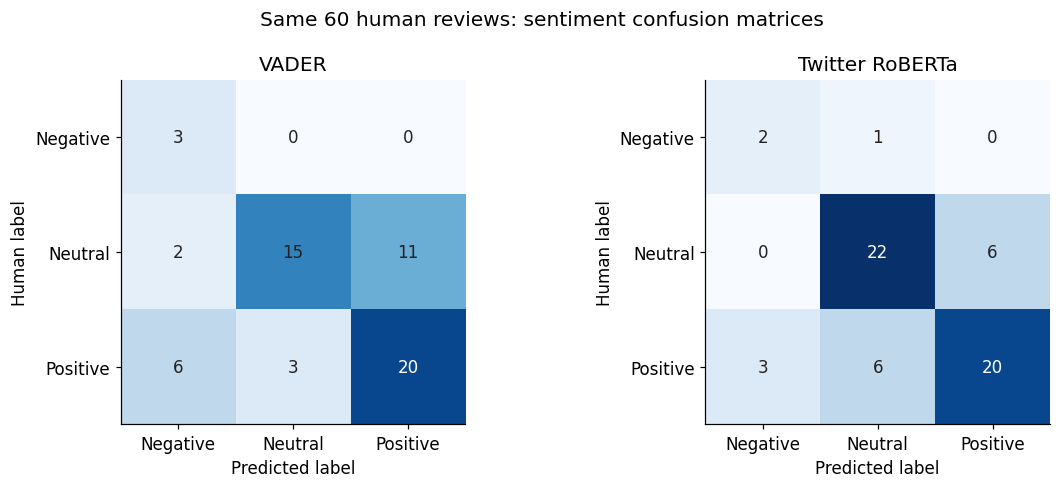

**Twitter RoBERTa: 16 disagreements.** Examples below retain the supplied reviewer explanations.

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for axis,name in zip(axes,['VADER','Twitter RoBERTa']):
    matrix=confusions[name]
    axis.imshow(matrix,cmap='Blues',vmin=0,vmax=max(m.max() for m in confusions.values()))
    axis.grid(False);axis.set(xticks=range(3),xticklabels=order,yticks=range(3),yticklabels=order,
                             xlabel='Predicted label',ylabel='Human label',title=name)
    for a in range(3):
        for b in range(3):axis.text(b,a,str(matrix[a,b]),ha='center',va='center',color='white' if matrix[a,b]>15 else '#222222')
fig.suptitle(f'Same {len(comparison_reviews)} human reviews: sentiment confusion matrices')
finish('12_sentiment_model_validation')
# Preserve every error for inspection; show full text for a bounded selection.
selected_errors=comparison_reviews[comparison_reviews.human_label.ne(comparison_reviews[selected_label_column])].copy()
selected_errors['selected_prediction']=selected_errors[selected_label_column]
selected_errors.to_csv(OUT/'selected_sentiment_validation_errors.csv',index=False)
say(f'**{SELECTED_SENTIMENT}: {len(selected_errors)} disagreements.** Examples below retain the supplied reviewer explanations.')
for row in selected_errors.head(6).itertuples():
    display(HTML(f'<p><b>Source {row.source_row}: human {row.human_label}; model {row.selected_prediction}</b></p>'
                 f'<p>{html.escape(row.text)}</p><p><i>Reviewer note:</i> {html.escape(row.notes)}</p>'))

## 9. Daily sentiment features — Q2.5; Q2.8
Daily aggregation matches available daily Bitcoin market candles. Within each date the sample is uniform, so means/proportions need no unequal record weights. We use mean polarity, polarity dispersion, positive and negative shares, and coverage/activity controls. Neutral share is reported descriptively but omitted from regression alongside an intercept; sentiment imbalance is not added because it equals positive minus negative share.

Days with fewer than 20 eligible English tweets are excluded from predictive modelling to avoid highly unstable sentiment means. This threshold is set before examining predictive performance. Missing sentiment is not filled with zero. Source volume measures dataset collection activity, not total social attention.

Compute both VADER and RoBERTa daily features on exactly the same tweets. The original VADER columns remain unchanged for reproducibility; `roberta_` columns are added for a separate controlled forecast comparison. The human-label winner determines which model is highlighted, not which forecast results are reported.

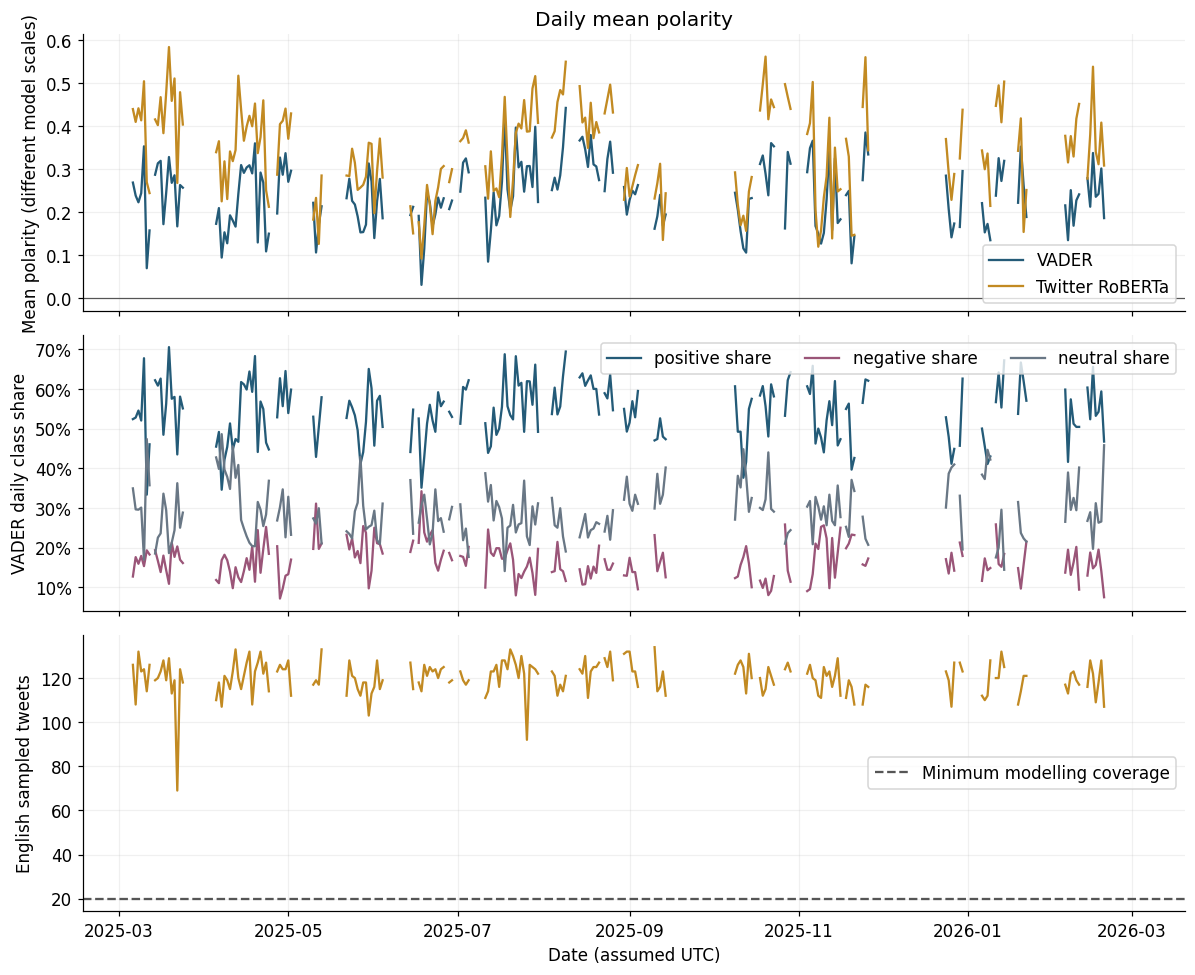

**201/201 observed English-sample dates** meet the 20-tweet threshold. Broken lines indicate missing dates. Changing language/sample coverage can change aggregate sentiment even without a change in the underlying population's opinions.

In [ ]:
tweets['positive']=tweets.sentiment_label.eq('Positive').astype(int)
tweets['negative']=tweets.sentiment_label.eq('Negative').astype(int)
daily=tweets.groupby('day').agg(mean_polarity=('polarity','mean'),polarity_sd=('polarity','std'),
     positive_share=('positive','mean'),negative_share=('negative','mean'),english_n=('source_row','size'),retweet_share=('is_retweet_flag','mean')).reset_index()
daily['neutral_share']=1-daily.positive_share-daily.negative_share
daily=daily.merge(daily_source,on='day',validate='one_to_one')
daily['log_source_volume']=np.log1p(daily.source_valid_records)
daily['english_sample_share']=daily.english_n/daily.day.map(day_sample_counts)
daily['adequate_coverage']=daily.english_n.ge(20)
# Parallel features on identical days: only the sentiment measurement changes.
tweets['roberta_positive_flag']=tweets.roberta_label.eq('Positive').astype(int)
tweets['roberta_negative_flag']=tweets.roberta_label.eq('Negative').astype(int)
roberta_daily=tweets.groupby('day').agg(
    roberta_mean_polarity=('roberta_polarity','mean'),roberta_polarity_sd=('roberta_polarity','std'),
    roberta_positive_share=('roberta_positive_flag','mean'),roberta_negative_share=('roberta_negative_flag','mean')).reset_index()
daily=daily.merge(roberta_daily,on='day',validate='one_to_one')
daily['roberta_neutral_share']=1-daily.roberta_positive_share-daily.roberta_negative_share
daily.to_csv(OUT/'daily_sentiment_features.csv',index=False)
fig,ax=plt.subplots(3,1,figsize=(11,9),sharex=True)
plot_daily=daily.set_index('day').reindex(full_dates)
ax[0].plot(plot_daily.index,plot_daily.mean_polarity,color=COLORS[0],label='VADER');ax[0].plot(plot_daily.index,plot_daily.roberta_mean_polarity,color=COLORS[1],label='Twitter RoBERTa');ax[0].legend();ax[0].axhline(0,color='#555555',linewidth=.8);ax[0].set(title='Daily mean polarity',ylabel='Mean polarity (different model scales)')
for col,color in [('positive_share',COLORS[0]),('negative_share',COLORS[2]),('neutral_share',COLORS[5])]:ax[1].plot(plot_daily.index,plot_daily[col],label=col.replace('_',' '),color=color)
ax[1].set(ylabel='VADER daily class share');ax[1].yaxis.set_major_formatter(PercentFormatter(1));ax[1].legend(ncol=3)
ax[2].plot(plot_daily.index,plot_daily.english_n,color=COLORS[1]);ax[2].axhline(20,color='#555555',linestyle='--',label='Minimum modelling coverage');ax[2].set(ylabel='English sampled tweets',xlabel='Date (assumed UTC)');ax[2].legend()
finish('07_daily_sentiment')
say(f"**{daily.adequate_coverage.sum()}/{len(daily)} observed English-sample dates** meet the 20-tweet threshold. "
    "Broken lines indicate missing dates. Changing language/sample coverage can change aggregate sentiment even without a change in the underlying population's opinions.")

## 10. Market data, volatility and the forecast clock — Q2.1; Q2.6–7
We use Yahoo Finance's `BTC-USD` daily OHLCV data via yfinance, cached as `data/bitcoin_market_daily.csv` with retrieval metadata. Source: [Yahoo Finance BTC-USD history](https://finance.yahoo.com/quote/BTC-USD/history/). Forty prior days initialise lags and rolling statistics; an extra future day supplies the final one-day target. Cached data are reused rather than silently revised on rerun.

\[
r_t=\log(P_t/P_{t-1}),\qquad v_t=|r_t|,\qquad y_t=|r_{t+1}|.
\]

Absolute daily log return measures movement magnitude and is a transparent, noisy proxy for realised volatility. It is not price direction. A trailing seven-day return standard deviation is an additional market predictor. Positive prices, a unique complete daily calendar and OHLC consistency are checked before shifting.

**Forecast origin:** just after the UTC close of day \(t\), using only information available through that close. **Target date:** \(t+1\). Targets and lagged features are created on the complete market calendar *before* joining tweet dates. A missing tweet date therefore cannot become an accidental multi-day return. A one-observation gap is also left at each train/test boundary. All scaling and model fitting occur inside the training period.

The UTC interpretation and source tweet timestamp credibility remain limitations; successful code execution cannot resolve them.

In [ ]:
market_path=DATA/'bitcoin_market_daily.csv'
start=(daily.day.min()-pd.Timedelta(days=40)).date()
end=(daily.day.max()+pd.Timedelta(days=3)).date()
if not market_path.exists():
    import yfinance as yf
    yf.set_tz_cache_location(str(DATA/'yfinance_cache'))
    downloaded=yf.download('BTC-USD',start=str(start),end=str(end),auto_adjust=False,progress=False,threads=False)
    if downloaded.empty:raise RuntimeError('Market download failed. Provide BTC-USD daily OHLCV as data/bitcoin_market_daily.csv.')
    if isinstance(downloaded.columns,pd.MultiIndex):downloaded.columns=downloaded.columns.get_level_values(0)
    downloaded=downloaded.reset_index();downloaded.to_csv(market_path,index=False)
    (DATA/'market_provenance.json').write_text(json.dumps({'source':'Yahoo Finance BTC-USD via yfinance','retrieved_utc':str(pd.Timestamp.now(tz='UTC')),'start':str(start),'end_exclusive':str(end)},indent=2))
market=pd.read_csv(market_path)
market['day']=pd.to_datetime(market['Date'],utc=True).dt.floor('D')
market=market.sort_values('day').reset_index(drop=True)
assert market.day.is_unique,'Duplicate market dates'
assert market.Close.gt(0).all(),'Nonpositive prices'
assert (market.High>=market.Low).all(),'Invalid market range'
assert market[['Open','High','Low','Close','Volume']].notna().all().all(),'Missing market fields'
assert market.day.diff().dropna().eq(pd.Timedelta(days=1)).all(),'Market calendar has gaps; fix before shift'
market['log_return']=np.log(market.Close/market.Close.shift(1))
market['abs_return']=market.log_return.abs()
market['rolling_volatility_7d']=market.log_return.rolling(7,min_periods=7).std()
market['market_range']=(market.High-market.Low)/market.Close
market['log_market_volume']=np.log1p(market.Volume)
market['abs_return_lag1']=market.abs_return.shift(1)
market['target_date']=market.day.shift(-1)
market['target_volatility']=market.abs_return.shift(-1)
market.to_csv(OUT/'market_features.csv',index=False)
merged=daily.merge(market,on='day',how='left',validate='one_to_one',indicator=True)
display(merged['_merge'].value_counts().to_frame('Dates'))
assert merged['_merge'].eq('both').all(),'Tweet dates lack market data'
assert (merged.target_date-merged.day).eq(pd.Timedelta(days=1)).all(),'Target is not next calendar day'
display(merged[['day','target_date','mean_polarity','abs_return','target_volatility']].head(6))
if (DATA/'market_provenance.json').exists():display(json.loads((DATA/'market_provenance.json').read_text()))

,Dates
_merge,
both,201
left_only,0
right_only,0


,day,target_date,mean_polarity,abs_return,target_volatility
0,2025-03-06 00:00:00+00:00,2025-03-07 00:00:00+00:00,0.269409,0.007330,0.036438
1,2025-03-07 00:00:00+00:00,2025-03-08 00:00:00+00:00,0.239213,0.036438,0.006803
2,2025-03-08 00:00:00+00:00,2025-03-09 00:00:00+00:00,0.223563,0.006803,0.066632
3,2025-03-09 00:00:00+00:00,2025-03-10 00:00:00+00:00,0.244824,0.066632,0.026005
4,2025-03-10 00:00:00+00:00,2025-03-11 00:00:00+00:00,0.353706,0.026005,0.053673
5,2025-03-11 00:00:00+00:00,2025-03-12 00:00:00+00:00,0.070301,0.053673,0.010327


{'source': 'Yahoo Finance BTC-USD via yfinance',
 'retrieved_utc': '2026-09-26 19:47:50.767787+00:00',
 'start': '2025-01-25',
 'end_exclusive': '2026-03-05',
 'rows': 404}

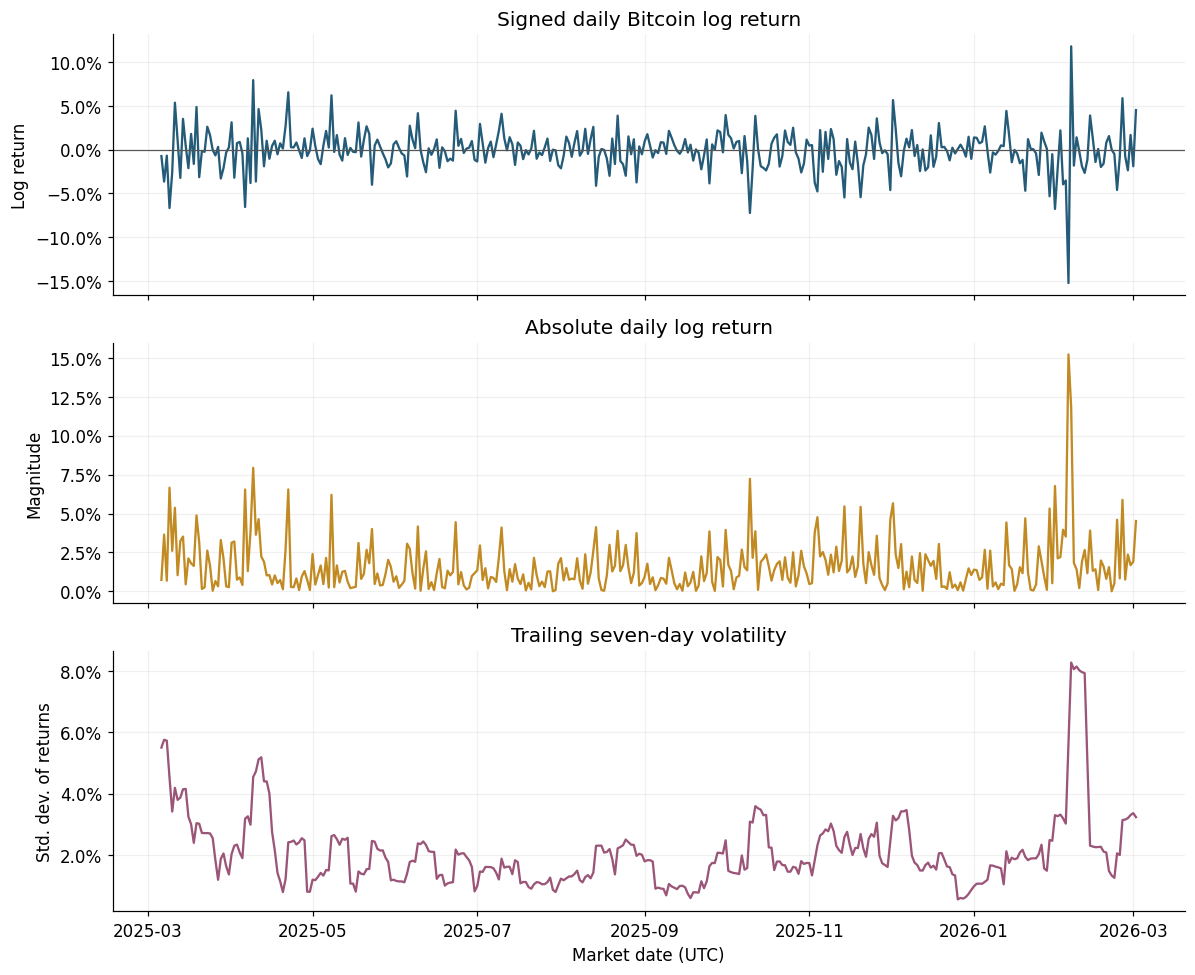

,mean_polarity,positive_share,negative_share,english_n,log_return,abs_return,rolling_volatility_7d,target_volatility
mean_polarity,1.000,0.910,-0.593,0.147,-0.100,-0.052,-0.154,-0.069
positive_share,0.910,1.000,-0.457,0.172,-0.133,-0.033,-0.142,-0.032
negative_share,-0.593,-0.457,1.000,-0.067,0.078,-0.109,-0.069,-0.040
english_n,0.147,0.172,-0.067,1.000,0.032,0.032,-0.028,-0.022
log_return,-0.100,-0.133,0.078,0.032,1.000,-0.122,0.009,-0.290
abs_return,-0.052,-0.033,-0.109,0.032,-0.122,1.000,0.449,0.314
rolling_volatility_7d,-0.154,-0.142,-0.069,-0.028,0.009,0.449,1.000,0.235
target_volatility,-0.069,-0.032,-0.040,-0.022,-0.290,0.314,0.235,1.000


Same-day mean polarity / absolute-return correlation is **-0.052**; mean polarity / next-day target correlation is **-0.069**. These are descriptive full-sample associations, not test-set performance, causal effects or a tuning criterion.

In [ ]:
fig,axes=plt.subplots(3,1,figsize=(11,9),sharex=True)
visible=market[market.day.between(daily.day.min(),daily.day.max())]
axes[0].plot(visible.day,visible.log_return,color=COLORS[0]);axes[0].axhline(0,color='#555555',linewidth=.8);axes[0].set(title='Signed daily Bitcoin log return',ylabel='Log return')
axes[1].plot(visible.day,visible.abs_return,color=COLORS[1]);axes[1].set(title='Absolute daily log return',ylabel='Magnitude')
axes[2].plot(visible.day,visible.rolling_volatility_7d,color=COLORS[2]);axes[2].set(title='Trailing seven-day volatility',ylabel='Std. dev. of returns',xlabel='Market date (UTC)')
for ax in axes:ax.yaxis.set_major_formatter(PercentFormatter(1))
finish('08_returns_and_volatility')
corr_cols=['mean_polarity','positive_share','negative_share','english_n','log_return','abs_return','rolling_volatility_7d','target_volatility']
correlations=merged[corr_cols].corr()
display(correlations.round(3));correlations.to_csv(OUT/'descriptive_correlations.csv')
say(f"Same-day mean polarity / absolute-return correlation is **{correlations.loc['mean_polarity','abs_return']:.3f}**; "
    f"mean polarity / next-day target correlation is **{correlations.loc['mean_polarity','target_volatility']:.3f}**. "
    "These are descriptive full-sample associations, not test-set performance, causal effects or a tuning criterion.")

## 11. Controlled model comparison and chronological evaluation — Q2.9–10
The primary comparison holds the algorithm and training/testing dates fixed:

- **Market Ridge:** market information only.
- **Market + activity Ridge:** adds source volume and language/retweet coverage controls.
- **Market + activity + sentiment Ridge:** adds polarity mean/dispersion and positive/negative shares.

The second-to-third comparison isolates the sentiment block more clearly than adding activity and sentiment together. Market-only and enhanced random forests provide a nonlinear sensitivity check, not a replacement for the controlled comparison. Persistence and training-mean predictions provide simple benchmarks.

The first 80% of eligible dates form the development period and the final 20% are an untouched chronological holdout. We evaluate four expanding-window folds inside development, with a one-observation boundary gap. Ridge uses a predeclared alpha of 10 and scaling fitted on training data; forest complexity is fixed in advance. No test-set tuning occurs. Every prediction is clipped at zero because volatility is nonnegative, identically across models. Missing-feature rows and sparse sentiment days are excluded explicitly.

MAE and RMSE are primary. SMAPE, test R² and high-volatility accuracy are supplementary. High-volatility labels use the training-target median only. R²'s reference is the test mean, so it is not a deployable baseline; actual training-mean performance is reported separately. The high-volatility metric is not price-direction accuracy.

**Extension:** both frozen sentiment methods receive separate Ridge and random-forest comparisons against the same activity-controlled models. The VADER specifications, dates and hyperparameters remain unchanged. The transformer was added after the original holdout results were inspected, so its forecast comparison is an exploratory extension, not a newly untouched confirmatory test. Human review dates also span the full source period; selection of the highlighted sentiment model is retrospective. Both forecast results remain visible to prevent selective reporting.

For continuity with the original exports, model names containing `+ sentiment` refer to **VADER**; models containing `+ RoBERTa` use the transformer.

### 11.1 Fix features, dates and model specifications

In [ ]:
# The original VADER model specifications are retained exactly.
market_features=['log_return','abs_return','abs_return_lag1','rolling_volatility_7d','market_range','log_market_volume']
activity_features=['log_source_volume','english_sample_share','retweet_share']
sentiment_features=['mean_polarity','polarity_sd','positive_share','negative_share']
all_features=market_features+activity_features+sentiment_features
roberta_features=['roberta_mean_polarity','roberta_polarity_sd','roberta_positive_share','roberta_negative_share']
roberta_all_features=market_features+activity_features+roberta_features
model_data=merged.loc[merged.adequate_coverage].dropna(subset=all_features+roberta_features+['target_volatility','target_date']).sort_values('day').reset_index(drop=True)
split=int(.8*len(model_data));development=model_data.iloc[:split].copy();holdout=model_data.iloc[split:].copy()
assert len(development)>=40 and len(holdout)>=10,'Insufficient independent daily observations'
specs={
 'Market Ridge':(market_features,'ridge'),
 'Market + activity Ridge':(market_features+activity_features,'ridge'),
 'Market + activity + sentiment Ridge':(all_features,'ridge'),
 'Market + activity + RoBERTa Ridge':(roberta_all_features,'ridge'),
 'Market + activity forest':(market_features+activity_features,'forest'),
 'Market + activity + RoBERTa forest':(roberta_all_features,'forest'),
 'Market forest':(market_features,'forest'),
 'Market + activity + sentiment forest':(all_features,'forest')}

### 11.2 Construct estimators

In [ ]:
def estimator(kind):
    if kind=='ridge':return make_pipeline(StandardScaler(),Ridge(alpha=10.))
    return RandomForestRegressor(n_estimators=160,max_depth=4,min_samples_leaf=8,random_state=SEED,n_jobs=1)

### 11.3 Fit each model and generate forecasts

In [ ]:
def fit_forecasts(train,test):
    # All learned preprocessing is fitted only on the training slice.
    forecasts={'Persistence':test.abs_return.to_numpy(),
               'Training mean':np.repeat(train.target_volatility.mean(),len(test))}
    fitted={}
    for name,(features,kind) in specs.items():
        model=estimator(kind)
        model.fit(train[features],train.target_volatility)
        forecasts[name]=np.maximum(model.predict(test[features]),0)
        fitted[name]=model
    return forecasts,fitted

### 11.4 Calculate metrics and retain dated predictions

In [ ]:
def score_forecasts(train,test,forecasts,phase,fold):
    actual=test.target_volatility.to_numpy()
    threshold=train.target_volatility.median()  # Never use test outcomes to set this threshold.
    rows=[];prediction_records=[]
    for name,pred in forecasts.items():
        rows.append({'phase':phase,'fold':fold,'model':name,'n_train':len(train),'n_test':len(test),
                     'train_last_origin':str(train.day.max().date()),
                     'test_first_origin':str(test.day.min().date()),'test_last_origin':str(test.day.max().date()),
                     'MAE':mean_absolute_error(actual,pred),'RMSE':np.sqrt(mean_squared_error(actual,pred)),
                     'SMAPE_percent':100*np.mean(2*np.abs(actual-pred)/(np.abs(actual)+np.abs(pred)+1e-12)),
                     'R2':r2_score(actual,pred),'high_volatility_accuracy':accuracy_score(actual>=threshold,pred>=threshold)})
        for origin,date,y,prediction in zip(test.day,test.target_date,actual,pred):
            prediction_records.append({'phase':phase,'fold':fold,'model':name,'forecast_origin':str(origin),
                                       'target_date':str(date),'actual':y,'prediction':float(prediction)})
    return rows,prediction_records

def evaluate(train,test,phase,fold):
    # A strict timestamp assertion protects the next-day forecast boundary.
    assert train.target_date.max()<test.day.min(),'Training target overlaps test origins'
    forecasts,fitted=fit_forecasts(train,test)
    rows,predictions=score_forecasts(train,test,forecasts,phase,fold)
    return rows,predictions,fitted

### 11.5 Run expanding validation and the final holdout

In [ ]:
metric_rows=[];prediction_rows=[]
for fold,(tr,te) in enumerate(TimeSeriesSplit(n_splits=4,gap=1).split(development),1):
    rows,preds,_=evaluate(development.iloc[tr],development.iloc[te],'Expanding validation',fold)
    metric_rows+=rows;prediction_rows+=preds
final_train=development.iloc[:-1].copy()
rows,preds,final_models=evaluate(final_train,holdout,'Final holdout',0)
metric_rows+=rows;prediction_rows+=preds

### 11.6 Export results and compare all benchmarks

In [ ]:
metrics=pd.DataFrame(metric_rows);predictions=pd.DataFrame(prediction_rows)
metrics.to_csv(OUT/'volatility_model_metrics.csv',index=False)
predictions.to_csv(OUT/'volatility_predictions.csv',index=False)
model_data.to_csv(OUT/'daily_modelling_dataset.csv',index=False)
display(metrics[metrics.phase.eq('Final holdout')][['model','n_train','n_test','MAE','RMSE','SMAPE_percent','R2','high_volatility_accuracy']].sort_values('MAE'))
display(metrics[metrics.phase.eq('Expanding validation')].groupby('model')[['MAE','RMSE']].agg(['mean','std']).round(5))
say(f"**{len(model_data)} eligible daily rows** remain from {len(merged)} sentiment dates. "
    f"Final training uses **{len(final_train)}** origins through {final_train.day.max().date()}; "
    f"holdout uses **{len(holdout)}** origins from {holdout.day.min().date()} to {holdout.day.max().date()}. "
    "One development row is purged before holdout. Validation folds are chronological and the test target remains unseen during fitting.")

,model,n_train,n_test,MAE,RMSE,SMAPE_percent,R2,high_volatility_accuracy
41,Training mean,159,41,0.011694,0.020087,75.160582,-0.003426,0.536585
47,Market + activity + RoBERTa forest,159,41,0.012206,0.018541,77.660600,0.145119,0.658537
46,Market + activity forest,159,41,0.012418,0.018493,78.504623,0.149506,0.658537
49,Market + activity + sentiment forest,159,41,0.012644,0.018638,79.403709,0.136128,0.634146
48,Market forest,159,41,0.012980,0.019778,80.264278,0.027187,0.609756
42,Market Ridge,159,41,0.013036,0.018700,79.571986,0.130391,0.536585
45,Market + activity + RoBERTa Ridge,159,41,0.013096,0.018321,80.500799,0.165275,0.560976
43,Market + activity Ridge,159,41,0.013199,0.018364,80.829917,0.161373,0.512195
44,Market + activity + sentiment Ridge,159,41,0.013267,0.018311,81.152688,0.166158,0.536585
40,Persistence,159,41,0.017252,0.025084,99.767351,-0.564683,0.512195


MAE              RMSE         
                                         mean      std     mean      std
model                                                                   
Market + activity + RoBERTa Ridge     0.01073  0.00347  0.01377  0.00419
Market + activity + RoBERTa forest    0.01079  0.00377  0.01375  0.00422
Market + activity + sentiment Ridge   0.01055  0.00253  0.01375  0.00385
Market + activity + sentiment forest  0.01072  0.00360  0.01376  0.00405
Market + activity Ridge               0.01033  0.00315  0.01330  0.00415
Market + activity forest              0.01043  0.00327  0.01342  0.00392
Market Ridge                          0.01008  0.00361  0.01309  0.00435
Market forest                         0.01089  0.00443  0.01383  0.00456
Persistence                           0.01198  0.00296  0.01633  0.00446
Training mean                         0.01190  0.00353  0.01451  0.00370

**201 eligible daily rows** remain from 201 sentiment dates. Final training uses **159** origins through 2025-11-18; holdout uses **41** origins from 2025-11-20 to 2026-03-02. One development row is purged before holdout. Validation folds are chronological and the test target remains unseen during fitting.

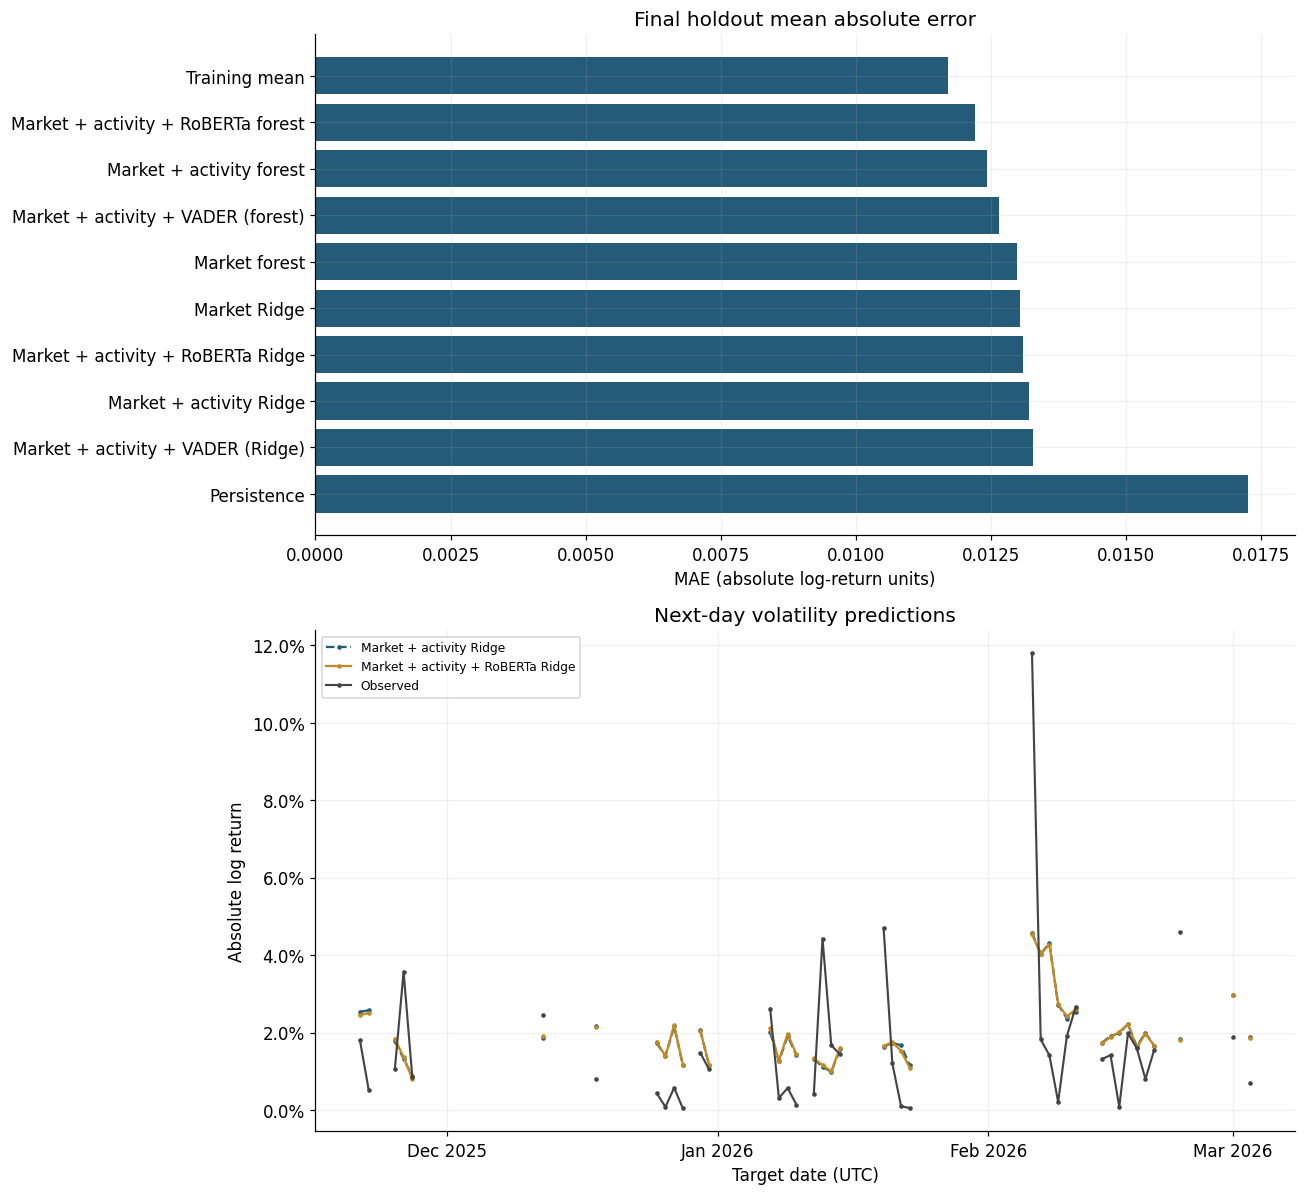

In [ ]:
primary='Market + activity + RoBERTa Ridge' if SELECTED_SENTIMENT=='Twitter RoBERTa' else 'Market + activity + sentiment Ridge'
control='Market + activity Ridge'
hold=metrics[metrics.phase.eq('Final holdout')].set_index('model')
fig,ax=plt.subplots(2,1,figsize=(12,11))
ranking=hold.sort_values('MAE')
short={'Market + activity + sentiment Ridge':'Market + activity + VADER (Ridge)',
       'Market + activity + sentiment forest':'Market + activity + VADER (forest)'}
ax[0].barh([short.get(x,x) for x in ranking.index][::-1],ranking.MAE.to_numpy()[::-1],color=COLORS[0]);ax[0].set(title='Final holdout mean absolute error',xlabel='MAE (absolute log-return units)')
p=predictions[predictions.phase.eq('Final holdout')].copy();p['target_date']=pd.to_datetime(p.target_date,utc=True)
for name,color,style in [('Market + activity Ridge',COLORS[0],'--'),(primary,COLORS[1],'-')]:
    q=p[p.model.eq(name)].set_index('target_date');q=q.reindex(pd.date_range(q.index.min(),q.index.max(),freq='D',tz='UTC'))
    ax[1].plot(q.index,q.prediction,label=short.get(name,name),color=color,linestyle=style,marker='.',markersize=4)
q=p[p.model.eq('Market Ridge')].set_index('target_date');q=q.reindex(pd.date_range(q.index.min(),q.index.max(),freq='D',tz='UTC'))
ax[1].plot(q.index,q.actual,label='Observed',color='#444444',linewidth=1.4,marker='.',markersize=4)
ax[1].set(title='Next-day volatility predictions',xlabel='Target date (UTC)',ylabel='Absolute log return');ax[1].yaxis.set_major_formatter(PercentFormatter(1));ax[1].legend(fontsize=8)
import matplotlib.dates as mdates
ax[1].xaxis.set_major_locator(mdates.MonthLocator());ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
finish('09_holdout_comparison')

RoBERTa sentiment slightly improves volatility predictions, while VADER slightly worsens them. However, the simple training-average benchmark achieves the lowest error overall. The prediction lines nearly overlap and miss large volatility spikes, suggesting that sentiment adds limited forecasting value and its benefit remains uncertain.

## 12. Interpretation, uncertainty and limitations — Q2.11

- **Can the model understand tweet sentiment?** Classification accuracy measures how often its Positive, Negative or Neutral labels match your human labels.
- **Can that sentiment help predict volatility?** Forecast accuracy measures how closely predicted price-movement sizes match actual movements. Better sentiment labels do not automatically produce better forecasts.

The block bootstrap estimates uncertainty by repeatedly resampling groups of seven neighbouring observations. These may span more than seven calendar days because some dates are missing. It measures uncertainty around the existing predictions; it does not capture uncertainty from retraining or choosing a different sentiment model.

A negative sentiment coefficient means more positive tweets are associated with smaller predicted price movements—not falling Bitcoin prices, and not proof that sentiment causes volatility to change

### 12.1 Quantify each sentiment model’s incremental forecast value

In [ ]:
def paired_forecast_effect(enhanced,control_name):
    base=p[p.model.eq(control_name)].sort_values('target_date')
    comparison=p[p.model.eq(enhanced)].sort_values('target_date')
    assert base.target_date.tolist()==comparison.target_date.tolist()
    lossdiff=np.abs(comparison.actual.to_numpy()-comparison.prediction.to_numpy())-np.abs(base.actual.to_numpy()-base.prediction.to_numpy())
    rng=np.random.default_rng(SEED);n=len(lossdiff);block=min(7,max(2,n//4));boot=[]
    for _ in range(2000):
        starts=rng.integers(0,n-block+1,size=int(np.ceil(n/block)))
        ids=np.concatenate([np.arange(start,start+block) for start in starts])[:n]
        boot.append(lossdiff[ids].mean())
    interval=np.quantile(boot,[.025,.975])
    folds=metrics[metrics.phase.eq('Expanding validation')].pivot(index='fold',columns='model',values='MAE')
    return {'enhanced_model':enhanced,'control':control_name,
            'mae_difference':float(hold.loc[enhanced,'MAE']-hold.loc[control_name,'MAE']),
            'mae_improvement_percent':100*(hold.loc[control_name,'MAE']-hold.loc[enhanced,'MAE'])/hold.loc[control_name,'MAE'],
            'rmse_improvement_percent':100*(hold.loc[control_name,'RMSE']-hold.loc[enhanced,'RMSE'])/hold.loc[control_name,'RMSE'],
            'ci_low':float(interval[0]),'ci_high':float(interval[1]),
            'validation_folds_improved':int((folds[enhanced]<folds[control_name]).sum())}
forecast_effects=pd.DataFrame([
    paired_forecast_effect('Market + activity + sentiment Ridge',control),
    paired_forecast_effect('Market + activity + RoBERTa Ridge',control),
    paired_forecast_effect('Market + activity + sentiment forest','Market + activity forest'),
    paired_forecast_effect('Market + activity + RoBERTa forest','Market + activity forest')])
forecast_effects.to_csv(OUT/'sentiment_incremental_forecast_effects.csv',index=False)
display(forecast_effects)
effect=forecast_effects.set_index('enhanced_model').loc[primary]
delta=float(effect.mae_difference);relative=float(effect.mae_improvement_percent)
ci=np.array([effect.ci_low,effect.ci_high]);wins=int(effect.validation_folds_improved)

,enhanced_model,control,mae_difference,mae_improvement_percent,rmse_improvement_percent,ci_low,ci_high,validation_folds_improved
0,Market + activity + sentiment Ridge,Market + activity Ridge,0.000068,-0.516290,0.285703,-0.000072,1.778344e-04,1
1,Market + activity + RoBERTa Ridge,Market + activity Ridge,-0.000103,0.781344,0.232927,-0.000186,3.356710e-07,1
2,Market + activity + sentiment forest,Market + activity forest,0.000226,-1.817994,-0.783408,-0.000044,5.751896e-04,0
3,Market + activity + RoBERTa forest,Market + activity forest,-0.000211,1.703149,-0.257595,-0.000513,7.601700e-05,2


- **RoBERTa** sentiment slightly reduces average forecast error: MAE improves by 0.78% for Ridge and 1.70% for random forest.
- **VADER** instead worsens MAE for both models. However, all confidence intervals include zero, and improvements are inconsistent across validation periods.

 RoBERTa therefore shows more promise than VADER, but there is no clear evidence of a reliable forecasting benefit.

### 12.2 Inspect conditional coefficient directions

In [ ]:
primary_features=specs[primary][0]
primary_sentiment_features=roberta_features if SELECTED_SENTIMENT=='Twitter RoBERTa' else sentiment_features
ridge=final_models[primary]
coefficients=pd.DataFrame({'feature':primary_features,'standardised_coefficient':ridge.named_steps['ridge'].coef_})
coefficients['group']=np.where(coefficients.feature.isin(primary_sentiment_features),'Sentiment',np.where(coefficients.feature.isin(activity_features),'Activity','Market'))
display(coefficients)
coefficients.to_csv(OUT/'ridge_standardised_coefficients.csv',index=False)
mean_feature='roberta_mean_polarity' if SELECTED_SENTIMENT=='Twitter RoBERTa' else 'mean_polarity'
mean_coef=float(coefficients.set_index('feature').loc[mean_feature,'standardised_coefficient'])
say(f"Holding the included predictors fixed, a one-training-standard-deviation increase in **{SELECTED_SENTIMENT} daily mean polarity** is associated with **{mean_coef:+.6f}** absolute-return units in the fitted Ridge prediction. "
    "The coefficient concerns movement size, not whether Bitcoin rises or falls. Correlated predictors, measurement error and source timing prevent a causal interpretation.")

,feature,standardised_coefficient,group
0,log_return,-0.001726,Market
1,abs_return,-0.002300,Market
2,abs_return_lag1,0.001654,Market
3,rolling_volatility_7d,0.000990,Market
4,market_range,0.004503,Market
5,log_market_volume,-0.001060,Market
6,log_source_volume,-0.002384,Activity
7,english_sample_share,0.000877,Activity
8,retweet_share,0.000000,Activity
9,roberta_mean_polarity,-0.000230,Sentiment


Holding the included predictors fixed, a one-training-standard-deviation increase in **Twitter RoBERTa daily mean polarity** is associated with **-0.000230** absolute-return units in the fitted Ridge prediction. The coefficient concerns movement size, not whether Bitcoin rises or falls. Correlated predictors, measurement error and source timing prevent a causal interpretation.

# Conclusion

### **Whether sentiment improves volatility modelling?**

RoBERTa is better at identifying sentiment in reviewed tweets, but its forecasting benefit is small and uncertain.
- It correctly labels 44 of 60 tweets, compared with 38 for VADER.
- Adding RoBERTa sentiment reduces Ridge’s average forecast error by 0.78%; adding VADER increases it by 0.52%.
- RoBERTa helps in only one of four validation periods, and its uncertainty interval includes zero, so the improvement is not convincing.
- Simply predicting the training-period average volatility still produces the lowest overall error.

The findings suggest that understanding tweet sentiment more accurately does not necessarily translate into reliably predicting Bitcoin volatility.

### **Is the relationship positive or negative?**
The selected RoBERTa Ridge model has a negative mean sentiment coefficient, approximately −0.000230.
- Holding other included predictors fixed, more positive sentiment is associated with lower predicted next day volatility.
- This concerns the size of price movements, not whether Bitcoin’s price rises or falls. The coefficient’s sign alone does not establish a statistically reliable relationship.

### **Does the evidence support association or causation?**
The notebook supports, at most, a tentative conditional association.
- It uses observational data: news, market conditions and other factors could influence both tweets and volatility, while market movements could themselves influence sentiment.
- Controlling for some predictors and respecting chronological order improves the analysis, but does not prove that sentiment causes volatility to change.

### **Limitations**

- Few negative examples: only three human-reviewed tweets are Negative, so performance on negative sentiment is uncertain.
- Ambiguous sentiment: a tweet might praise Bitcoin while criticising another cryptocurrency, making its overall label unclear.
- Language and data problems: models can misunderstand slang or sarcasm. Dates are unverified, some days are missing, and the English-only sample may not represent wider discussion.
- Difficult prediction task: daily price-movement sizes fluctuate unpredictably, and the short test period may be strongly influenced by a few unusual days.

Therefore, the results shows possible relationships and differences in prediction accuracy. It does not prove that tweet sentiment causes Bitcoin volatility or establish a reliable trading strategy.

## References and reproducibility notes

1. University of the Free State. *EDAB6808 Assignment 4: Natural Language Processing of Bitcoin Tweets*. Supplied assignment brief, 2026; two questions of 50 marks each. No per-item mark allocation was supplied.
2. [Kaggle dataset, version 1](https://www.kaggle.com/datasets/pokeash/bitcoin-tweets-dataset-20252026). Local source hash and recovery details: `data/data_provenance.json`.
3. Hutto, C. J., & Gilbert, E. (2014). *VADER: A Parsimonious Rule-based Model for Sentiment Analysis of Social Media Text*. ICWSM. [Author's implementation and scoring](https://github.com/cjhutto/vaderSentiment).
4. [Scikit-learn topic extraction example: NMF and LDA](https://scikit-learn.org/stable/auto_examples/applications/plot_topics_extraction_with_nmf_lda.html); [LDA API](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.LatentDirichletAllocation.html); [NMF API](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.NMF.html).
5. [Scikit-learn chronological splitting](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html), [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html), and [random forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).
6. [Yahoo Finance BTC-USD historical data](https://finance.yahoo.com/quote/BTC-USD/history/) accessed through [yfinance](https://ranaroussi.github.io/yfinance/). Retrieval metadata and cached candles are included.
7. [langdetect](https://pypi.org/project/langdetect/) for seeded language classification. Probabilities are classifier outputs, not calibrated guarantees that a tweet is English.


8. [CardiffNLP Twitter RoBERTa model card](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest), pinned revision recorded in `data/twitter_roberta_provenance.json`; [TimeLMs paper](https://aclanthology.org/2022.acl-demo.25/).
9. [WordCloud documentation](https://amueller.github.io/word_cloud/): topic component weights are used as frequencies for display only.